In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

import sys
import os

sys.path.insert(0, os.path.join(os.getcwd(), "..", "scripts"))
from utility_functions import overlap, charge, AD_coords, non_overlap_ADs_count_v2, overlap_AD_count_v2, calculate_f1, predictions_with_ADs, ADs_with_predictions

In [50]:
# Read in predictions from individual predictors
individual_predictions = pd.read_csv('arf_seqs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })

# Convert to lists of tuples
individual_predictions['adhunter_intervals'] = individual_predictions['adhunter_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_intervals'] = individual_predictions['tada_intervals'].fillna('[]').apply(ast.literal_eval)

individual_predictions['tada_centers'] = individual_predictions['tada_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_preds'] = individual_predictions['tada_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['adpred_intervals'] = individual_predictions['adpred_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['paddle_intervals'] = individual_predictions['paddle_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_intervals'] = individual_predictions['adhunter_ensemble_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['composition_intervals'] = individual_predictions['composition_intervals'].fillna('[]').apply(ast.literal_eval)

In [133]:
# Read in parrot model predictions
with open('arf_seqs_consensus_all_six_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds = pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})

In [134]:
consensus_names = consensus_preds['name']

# Read in experimental data
data = pd.read_csv('arf_seqs_w_ADs.csv', index_col=0)
data['ad_charge'] = data['sequence'].apply(charge)
# Drop rows with identical sequences
data = data[[n in set(consensus_names) for n in data['name']]]
data

,sequence,name,weak_ads,medium_ads,strong_ads,ad_charge
0,PVITPFYICPPPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDF...,AL1G31800|AL1G31800.t1,['PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKDAQSS...,['PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKDAQSS...,"['PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKD', '...",31
1,TPESLFIFPSLTSGLKRQLHPSYFAGETEWGSLIKRPLIRVPDSAN...,AL1G32580|AL1G32580.t1,['KVNQLLQKPGASSPVQADPCLDISQQIYPPQSDPINGFSFLETD...,['ASSPVQADPCLDISQQIYPPQSDPINGFSFLETDELTSQVSSFQ...,['ASSPVQADPCLDISQQIYPPQSDPINGFSFLETDELTSQVSSFQ...,32
2,PLTTFPMYPSPFPLRLKRPWPPGLPSFHGLKEDDMGMSMSSPLMWD...,AL1G44270|AL1G44270.t1,"['PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN', '...",['PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN'],['PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN'],17
3,HLIPSSSISQPTVLQKKRARQCNEIGSTSSNLLTGQEIGQSSLSSP...,AL1G48670|AL1G48670.t2,['NLLTGQEIGQSSLSSPKSVPEFSCRDAVEDSKFPSDWLMSDLVP...,[],[],16
4,HSTPSSNVLPSSMLKNKRSREFNEIGSSSSHLLPPILTQGQEIGQP...,AL1G48960|AL1G48960.t1,['QEIGQPSMTSPMNVPLSYRDAIEDDSTPSRLLMSYSVQTM'],['QEIGQPSMTSPMNVPLSYRDAIEDDSTPSRLLMSYSVQTM'],[],12
...,...,...,...,...,...,...
363,PSAAPTAINPPPIPRAKRPRTNVPSPSDVSHLSREGLPRGMTEHSQ...,evm_27.TU.AmTr_v1.0_scaffold00057.126|evm_27.m...,[],[],[],18
364,PLTTFPMYPSPFPLRLKRPWPPGLPSLHGNKDDDLGMSAPLMWLRD...,evm_27.TU.AmTr_v1.0_scaffold00092.36|evm_27.mo...,"['PPGLPSLHGNKDDDLGMSAPLMWLRDGADRNMQSLNFQGL', '...",['SHQLQHQHSFNDQQQQNSQHNSQQNQQQLPDQQQTQQQQF'],['SHQLQHQHSFNDQQQQNSQHNSQQNQQQLPDQQQTQQQQF'],29
365,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFA...,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,['RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS'],[],[],12
366,VVSNIPTLQISPFSLPKKKHRISHPDFSSLDGTHCSLVGPTPTLPP...,evm_27.TU.AmTr_v1.0_scaffold00155.56|evm_27.mo...,[],[],[],24


In [78]:
def make_tada_intervals(preds, threshold=0.4):
    # Expanding so one row per tiles
    tada_preds_expanded = preds[["name", "tada_centers", "tada_preds"]].explode(['tada_centers', 'tada_preds']).reset_index()
    tada_preds_expanded["Start"] = tada_preds_expanded["tada_centers"] - 20
    tada_preds_expanded["End"] = tada_preds_expanded["tada_centers"] + 20
    
    # Filtering to active rows
    active_preds = tada_preds_expanded[tada_preds_expanded["tada_preds"] > threshold]
    active_tile_coords = active_preds[["name", "Start", "End"]]
    active_tile_coords.reset_index(inplace= True,drop=True)
    
    # Merging intervals on same protein
    dfs = []
    i = 0
    for name in active_tile_coords["name"].unique():
        dfs.append(return_merged_row(name, active_tile_coords))

    # Check if there are any predicted activation domains
    if len(dfs) > 0: 
        merged_active_tile_coords = pd.concat(dfs)
        merged_active_tile_coords = merged_active_tile_coords.reset_index(drop = True)
        tada_intervals = merged_active_tile_coords
        tada_intervals["predictor"] = "TADA"
        return tada_intervals
    else:
        return None

def return_merged_row(name, df):
    # Only look at rows with the same name
    same_name_rows = df[df["name"] == name]
    same_name_rows = same_name_rows.sort_values(by = "Start")
    
    # Final dataframe columns
    new_starts = []
    new_ends = []
    orig_name = []
    
    # Current row's values
    curr_start = -1
    curr_end = -1
    curr_orig_name = []
    
    for i in same_name_rows.index:
        # Merge current row with next row
        if curr_end >= same_name_rows.loc[i]["Start"]:
            curr_end = max(curr_end, same_name_rows.loc[i]["End"])
        
        # Don't merge current row with next row
        else: 
            new_starts.append(curr_start)
            new_ends.append(curr_end)

            curr_orig_name = [str(c) for c in curr_orig_name]            
            
            curr_start = same_name_rows.loc[i]["Start"]
            curr_end = same_name_rows.loc[i]["End"]
    
    # Append the last values
    new_starts.append(curr_start)
    new_ends.append(curr_end)
    
    

    # curr_matching_isoforms = [c for c in curr_matching_isoforms]
    curr_orig_name = [str(c) for c in curr_orig_name]
    orig_name.append(" / ".join(curr_orig_name))
    
    # Remove the first (because it is just -1 or "")
    new_starts = new_starts[1:]
    new_ends = new_ends[1:]
    orig_name = orig_name[1:]
    
    return pd.DataFrame({"name" :name,
                         "Start": new_starts,
                        "End": new_ends
                        })
    

In [137]:
data['real_AD_coords'] = data.apply(get_AD_coords, axis=1)
data['real_AD_coords'] = data.apply(get_AD_coords, axis=1)

In [129]:
# Beacuse the threshold biases the F1 score so much, I think PRC curves are a better choice

def calculate_precision_recall_TADA(threshold):
    tada_intervals = make_tada_intervals(individual_predictions, threshold)
    if tada_intervals is None: 
        return 0, 1
    tada_intervals["Start"] = tada_intervals["Start"].astype(int)
    tada_intervals["End"] = tada_intervals["End"].astype(int)
    tada_intervals = tada_intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')

    merged = tada_intervals.merge(data, on='name', how='right')
    merged['TADA'] = merged['TADA'].apply(lambda x: x if isinstance(x, list) else [])
    total_positive = sum([len(ast.literal_eval(ls)) for ls in merged['medium_ads']]) # Number of true ADs

    merged['TADA_recall_TP'] = merged.apply(ADs_with_predictions, ad_coords_col='TADA', axis=1)
    tada_r = merged['TADA_recall_TP'].sum() / total_positive

    merged['TADA_precision_TP'] = merged.apply(predictions_with_ADs, ad_coords_col='TADA', axis=1)
    total_predictions = sum([len(ls) for ls in merged['TADA']]) # Number of predicted ADs
    tada_p = merged['TADA_precision_TP'].sum() / total_predictions

    return tada_r, tada_p

In [101]:
consensus_preds

,name,sequence,preds
0,AL1G31800|AL1G31800.t1,PVITPFYICPPPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDF...,"[0.13282713, 0.14799719, 0.1953486, 0.23053452..."
1,AL1G32580|AL1G32580.t1,TPESLFIFPSLTSGLKRQLHPSYFAGETEWGSLIKRPLIRVPDSAN...,"[0.12738425, 0.123937115, 0.113760464, 0.05158..."
2,AL1G44270|AL1G44270.t1,PLTTFPMYPSPFPLRLKRPWPPGLPSFHGLKEDDMGMSMSSPLMWD...,"[0.07611333, 0.045856364, 0.045820996, 0.06297..."
3,AL1G48670|AL1G48670.t2,HLIPSSSISQPTVLQKKRARQCNEIGSTSSNLLTGQEIGQSSLSSP...,"[0.003758151, -0.024813168, -0.030465834, -0.0..."
4,AL1G48960|AL1G48960.t1,HSTPSSNVLPSSMLKNKRSREFNEIGSSSSHLLPPILTQGQEIGQP...,"[-0.004459489, -0.018622428, -0.022283856, -0...."
...,...,...,...
350,evm_27.TU.AmTr_v1.0_scaffold00057.126|evm_27.m...,PSAAPTAINPPPIPRAKRPRTNVPSPSDVSHLSREGLPRGMTEHSQ...,"[-0.0093946755, -0.021777056, -0.021878079, -0..."
351,evm_27.TU.AmTr_v1.0_scaffold00092.36|evm_27.mo...,PLTTFPMYPSPFPLRLKRPWPPGLPSLHGNKDDDLGMSAPLMWLRD...,"[0.074612334, 0.043354705, 0.0405157, 0.054252..."
352,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFA...,"[0.00955173, -0.007896211, -0.019990314, -0.01..."
353,evm_27.TU.AmTr_v1.0_scaffold00155.56|evm_27.mo...,VVSNIPTLQISPFSLPKKKHRISHPDFSSLDGTHCSLVGPTPTLPP...,"[0.009865002, -0.0031696158, -0.013626652, -0...."


In [117]:
# Beacuse the threshold biases the F1 score so much, I think PRC curves are a better choice

def calculate_precision_recall_parrot(threshold):
    consensus_preds['predicted_AD_coords'] = consensus_preds['preds'].apply(AD_coords, threshold=threshold)

    merged = consensus_preds.merge(data, on='name', how='right')
    total_positive = sum([len(ast.literal_eval(ls)) for ls in merged['medium_ads']]) # Number of true ADs

    merged['parrot_recall_TP'] = merged.apply(ADs_with_predictions, ad_coords_col='predicted_AD_coords', axis=1)
    parrot_r = merged['parrot_recall_TP'].sum()  / total_positive

    merged['parrot_precision_TP'] = merged.apply(predictions_with_ADs, ad_coords_col='predicted_AD_coords', axis=1)
    total_predictions = sum([len(ls) for ls in merged['predicted_AD_coords']]) # Number of predicted ADs
    print(merged['parrot_precision_TP'].sum() )
    parrot_p = merged['parrot_precision_TP'].sum() / total_predictions

    return parrot_r, parrot_p

In [125]:
calculate_precision_recall_parrot(0)

208


(np.float64(0.9473684210526315), np.float64(0.20233463035019456))

In [138]:
parrot_recalls = []
parrot_precisions = []

for threshold in np.arange(0, 1.05, 0.05):
    r, p = calculate_precision_recall_parrot(threshold)
    parrot_recalls.append(r)
    parrot_precisions.append(p)    

208
188
170
164
162
150
134
120
87
64
49
35
32
24
18
18
16
12
7
2
0


/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_47718/2194858506.py:15: RuntimeWarning: invalid value encountered in scalar divide
  parrot_p = merged['parrot_precision_TP'].sum() / total_predictions


In [139]:
tada_recalls = []
tada_precisions = []

for threshold in np.arange(0, 1.05, 0.05):
    # print(threshold)
    r, p = calculate_precision_recall_TADA(threshold)
    tada_recalls.append(r)
    tada_precisions.append(p)    

/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_47718/4291033621.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tada_intervals = tada_intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_47718/4291033621.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tada_intervals = tada

Text(0, 0.5, 'Precision')

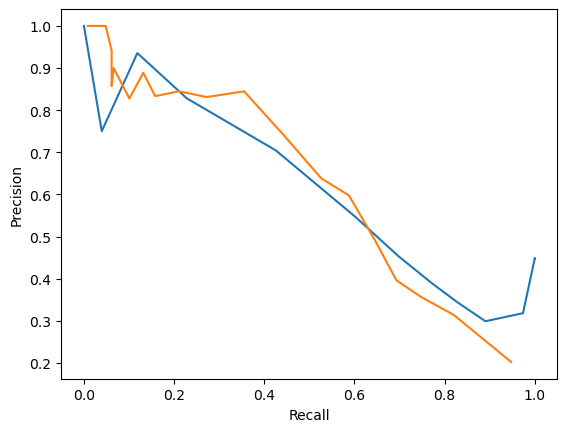

In [140]:
plt.plot(tada_recalls, tada_precisions)
plt.plot(parrot_recalls, parrot_precisions)
plt.xlabel("Recall")
plt.ylabel("Precision")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

grid = np.quantile(tada_precisions, np.linspace(0, 1, 200))
n_regions = [sum(len(score_to_regions(p, t)) for _, p in dataset) for t in grid]

plt.plot(grid, n_regions)
plt.xlabel('threshold'); plt.ylabel('# predicted regions (all proteins)')

In [4]:
# Check no duplicates
individual_predictions['name'].value_counts()

name
AL1G31800|AL1G31800.t1                                                        1
Medtr5g460740|Medtr5g460740.1                                                 1
Migut.A00611|Migut.A00611.1                                                   1
Medtr8g446900|Medtr8g446900.1                                                 1
Medtr8g101360|Medtr8g101360.1                                                 1
                                                                             ..
Brara.H02354|Brara.H02354.1                                                   1
Brara.H01893|Brara.H01893.1                                                   1
Brara.G03536|Brara.G03536.1                                                   1
Brara.G02608|Brara.G02608.1                                                   1
evm_27.TU.AmTr_v1.0_scaffold00211.4|evm_27.model.AmTr_v1.0_scaffold00211.4    1
Name: count, Length: 368, dtype: int64

In [6]:
# Parrot does not rerun on identical sequences! 
len(consensus_preds)

355

In [7]:
len(individual_predictions)

368

In [ ]:
# Merge predictions
merged_individual = individual_predictions.merge(data, on=['name', 'sequence'], how='right')
merged_consensus = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

# Get AD coordinates from parrot model
merged_consensus['predicted_AD_coords'] = merged_consensus['preds'].apply(AD_coords, threshold=0.4)

In [34]:
len(merged_consensus)

355

In [35]:
def get_AD_coords(row, column='medium_ads'):
    ad_seqs = ast.literal_eval(row[column])
    sequence = row['sequence']

    coords = []

    for seq in ad_seqs: 
        start = sequence.find(seq) 
        end = start + len(seq)
        coords.append((start, end))

        # Check 
        if sequence[start:end] != seq:
            print(sequence)
            print(seq)
            print("ERROR")
    
    return coords

In [36]:
merged_consensus['real_AD_coords'] = merged_consensus.apply(get_AD_coords, axis=1)
merged_individual['real_AD_coords'] = merged_individual.apply(get_AD_coords, axis=1)

In [38]:
# Calculate recall (TP / total Positive)
# Here, true positives are defined based on the AD (i.e. if two predictions overlap with one AD, it is counted as 1)
total_positive = sum([len(ast.literal_eval(ls)) for ls in merged_individual['medium_ads']]) # Number of true ADs

merged_individual['adpred_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adpred_intervals', axis=1)
adpred_r  = merged_individual['adpred_recall_TP'].sum() / total_positive

merged_individual['TADA_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='tada_intervals', axis=1)
tada_r = merged_individual['TADA_recall_TP'].sum() / total_positive

merged_individual['adhunterlite_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adhunter_intervals', axis=1)
adhunterlite_r = merged_individual['adhunterlite_recall_TP'].sum() / total_positive

merged_individual['adhunterensemble_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adhunter_ensemble_intervals', axis=1)
adhunterensemble_r = merged_individual['adhunterensemble_recall_TP'].sum() / total_positive

merged_individual['paddle_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='paddle_intervals', axis=1)
paddle_r = merged_individual['paddle_recall_TP'].sum() / total_positive

merged_individual['composition_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='composition_intervals', axis=1)
composition_r = merged_individual['composition_recall_TP'].sum() / total_positive

merged_consensus['parrot_recall_TP'] = merged_consensus.apply(ADs_with_predictions, ad_coords_col='predicted_AD_coords', axis=1)
parrot_r = merged_consensus['parrot_recall_TP'].sum()  / total_positive

In [39]:
# Calculate precision (TP / total predicted)
# Here, true positives are defined based on the AD (i.e. if two predictions overlap with one AD, it is counted as 1)

merged_individual['adpred_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adpred_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adpred_intervals']]) # Number of predicted ADs
adpred_p  = merged_individual['adpred_precision_TP'].sum() / total_predictions

merged_individual['TADA_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='tada_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['tada_intervals']]) # Number of predicted ADs
tada_p = merged_individual['TADA_precision_TP'].sum() / total_predictions

merged_individual['adhunterlite_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adhunter_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adhunter_intervals']]) # Number of predicted ADs
adhunterlite_p = merged_individual['adhunterlite_precision_TP'].sum() / total_predictions

merged_individual['adhunterensemble_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adhunter_ensemble_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adhunter_ensemble_intervals']]) # Number of predicted ADs
adhunterensemble_p = merged_individual['adhunterensemble_precision_TP'].sum() / total_predictions

merged_individual['paddle_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='paddle_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['paddle_intervals']]) # Number of predicted ADs
paddle_p = merged_individual['paddle_precision_TP'].sum() / total_predictions

merged_individual['composition_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='composition_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['composition_intervals']]) # Number of predicted ADs
composition_p = merged_individual['composition_precision_TP'].sum() / total_predictions

merged_consensus['parrot_precision_TP'] = merged_consensus.apply(predictions_with_ADs, ad_coords_col='predicted_AD_coords', axis=1)
total_predictions = sum([len(ls) for ls in merged_consensus['predicted_AD_coords']]) # Number of predicted ADs
parrot_p = merged_consensus['parrot_precision_TP'].sum()  / total_positive

In [40]:
adpred_f1 = calculate_f1(adpred_p, adpred_r)
tada_f1 = calculate_f1(tada_p, tada_r)
adhunterlite_f1 = calculate_f1(adhunterlite_p, adhunterlite_r)
adhunterensemble_f1 = calculate_f1(adhunterensemble_p, adhunterensemble_r)
paddle_f1 = calculate_f1(paddle_p, paddle_r)
composition_f1 = calculate_f1(composition_p, composition_r)
parrot_f1 = calculate_f1(parrot_p, parrot_r)

In [41]:
print("Model\tprecision\trecall\t")
print(f'ADpred\t{adpred_p:.3}\t{adpred_r:.3}\t{adpred_f1:.3}')
print(f'TADA\t{tada_p:.3}\t{tada_r:.3}\t{tada_f1:.3}')
print(f'ADhunterLite\t{adhunterlite_p:.3}\t{adhunterlite_r:.3}\t{adhunterlite_f1:.3}')
print(f'ADhunterEnsemble\t{adhunterensemble_p:.3}\t{adhunterensemble_r:.3}\t{adhunterensemble_f1:.3}')
print(f'PADDLE\t{paddle_p:.3}\t{paddle_r:.3}\t{paddle_f1:.3}')
print(f'Composition\t{composition_p:.3}\t{composition_r:.3}\t{composition_f1:.3}')
print(f'Parrot consensus\t{parrot_r:.3}\t{parrot_p:.3}\t{parrot_f1:.3}')

Model	precision	recall	
ADpred	0.842	0.127	0.221
TADA	0.453	0.697	0.55
ADhunterLite	0.441	0.566	0.495
ADhunterEnsemble	0.707	0.259	0.379
PADDLE	0.713	0.373	0.49
Composition	0.533	0.0351	0.0658
Parrot consensus	0.355	0.382	0.368


# For strong ADs

In [42]:
merged_consensus['real_AD_coords'] = merged_consensus.apply(get_AD_coords, column='strong_ads', axis=1)
merged_individual['real_AD_coords'] = merged_individual.apply(get_AD_coords, column='strong_ads', axis=1)

# Calculate recall (TP / total Positive)
# Here, true positives are defined based on the AD (i.e. if two predictions overlap with one AD, it is counted as 1)
total_positive = sum([len(ast.literal_eval(ls)) for ls in merged_individual['strong_ads']]) # Number of true ADs

merged_individual['adpred_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adpred_intervals', axis=1)
adpred_r  = merged_individual['adpred_recall_TP'].sum() / total_positive

merged_individual['TADA_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='tada_intervals', axis=1)
tada_r = merged_individual['TADA_recall_TP'].sum() / total_positive

merged_individual['adhunterlite_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adhunter_intervals', axis=1)
adhunterlite_r = merged_individual['adhunterlite_recall_TP'].sum() / total_positive

merged_individual['adhunterensemble_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adhunter_ensemble_intervals', axis=1)
adhunterensemble_r = merged_individual['adhunterensemble_recall_TP'].sum() / total_positive

merged_individual['paddle_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='paddle_intervals', axis=1)
paddle_r = merged_individual['paddle_recall_TP'].sum() / total_positive

merged_individual['composition_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='composition_intervals', axis=1)
composition_r = merged_individual['composition_recall_TP'].sum() / total_positive

merged_consensus['parrot_recall_TP'] = merged_consensus.apply(ADs_with_predictions, ad_coords_col='predicted_AD_coords', axis=1)
parrot_r = merged_consensus['parrot_recall_TP'].sum()  / total_positive

# Calculate precision (TP / total predicted)
# Here, true positives are defined based on the AD (i.e. if two predictions overlap with one AD, it is counted as 1)

merged_individual['adpred_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adpred_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adpred_intervals']]) # Number of predicted ADs
adpred_p  = merged_individual['adpred_precision_TP'].sum() / total_predictions

merged_individual['TADA_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='tada_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['tada_intervals']]) # Number of predicted ADs
tada_p = merged_individual['TADA_precision_TP'].sum() / total_predictions

merged_individual['adhunterlite_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adhunter_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adhunter_intervals']]) # Number of predicted ADs
adhunterlite_p = merged_individual['adhunterlite_precision_TP'].sum() / total_predictions

merged_individual['adhunterensemble_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adhunter_ensemble_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adhunter_ensemble_intervals']]) # Number of predicted ADs
adhunterensemble_p = merged_individual['adhunterensemble_precision_TP'].sum() / total_predictions

merged_individual['paddle_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='paddle_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['paddle_intervals']]) # Number of predicted ADs
paddle_p = merged_individual['paddle_precision_TP'].sum() / total_predictions

merged_individual['composition_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='composition_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['composition_intervals']]) # Number of predicted ADs
composition_p = merged_individual['composition_precision_TP'].sum() / total_predictions

merged_consensus['parrot_precision_TP'] = merged_consensus.apply(predictions_with_ADs, ad_coords_col='predicted_AD_coords', axis=1)
total_predictions = sum([len(ls) for ls in merged_consensus['predicted_AD_coords']]) # Number of predicted ADs
parrot_p = merged_consensus['parrot_precision_TP'].sum()  / total_positive

# Calcualte F1
adpred_f1 = calculate_f1(adpred_p, adpred_r)
tada_f1 = calculate_f1(tada_p, tada_r)
adhunterlite_f1 = calculate_f1(adhunterlite_p, adhunterlite_r)
adhunterensemble_f1 = calculate_f1(adhunterensemble_p, adhunterensemble_r)
paddle_f1 = calculate_f1(paddle_p, paddle_r)
composition_f1 = calculate_f1(composition_p, composition_r)
parrot_f1 = calculate_f1(parrot_p, parrot_r)

print("Model\tprecision\trecall\t")
print(f'ADpred\t{adpred_p:.3}\t{adpred_r:.3}\t{adpred_f1:.3}')
print(f'TADA\t{tada_p:.3}\t{tada_r:.3}\t{tada_f1:.3}')
print(f'ADhunterLite\t{adhunterlite_p:.3}\t{adhunterlite_r:.3}\t{adhunterlite_f1:.3}')
print(f'ADhunterEnsemble\t{adhunterensemble_p:.3}\t{adhunterensemble_r:.3}\t{adhunterensemble_f1:.3}')
print(f'PADDLE\t{paddle_p:.3}\t{paddle_r:.3}\t{paddle_f1:.3}')
print(f'Composition\t{composition_p:.3}\t{composition_r:.3}\t{composition_f1:.3}')
print(f'Parrot consensus\t{parrot_r:.3}\t{parrot_p:.3}\t{parrot_f1:.3}')

Model	precision	recall	
ADpred	0.737	0.176	0.285
TADA	0.309	0.732	0.435
ADhunterLite	0.304	0.608	0.405
ADhunterEnsemble	0.585	0.346	0.435
PADDLE	0.537	0.444	0.486
Composition	0.4	0.0458	0.0821
Parrot consensus	0.431	0.451	0.441


# Weak ADs

In [44]:
merged_consensus['real_AD_coords'] = merged_consensus.apply(get_AD_coords, column='weak_ads', axis=1)
merged_individual['real_AD_coords'] = merged_individual.apply(get_AD_coords, column='weak_ads', axis=1)

# Calculate recall (TP / total Positive)
# Here, true positives are defined based on the AD (i.e. if two predictions overlap with one AD, it is counted as 1)
total_positive = sum([len(ast.literal_eval(ls)) for ls in merged_individual['weak_ads']]) # Number of true ADs

merged_individual['adpred_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adpred_intervals', axis=1)
adpred_r  = merged_individual['adpred_recall_TP'].sum() / total_positive

merged_individual['TADA_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='tada_intervals', axis=1)
tada_r = merged_individual['TADA_recall_TP'].sum() / total_positive

merged_individual['adhunterlite_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adhunter_intervals', axis=1)
adhunterlite_r = merged_individual['adhunterlite_recall_TP'].sum() / total_positive

merged_individual['adhunterensemble_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='adhunter_ensemble_intervals', axis=1)
adhunterensemble_r = merged_individual['adhunterensemble_recall_TP'].sum() / total_positive

merged_individual['paddle_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='paddle_intervals', axis=1)
paddle_r = merged_individual['paddle_recall_TP'].sum() / total_positive

merged_individual['composition_recall_TP'] = merged_individual.apply(ADs_with_predictions, ad_coords_col='composition_intervals', axis=1)
composition_r = merged_individual['composition_recall_TP'].sum() / total_positive

merged_consensus['parrot_recall_TP'] = merged_consensus.apply(ADs_with_predictions, ad_coords_col='predicted_AD_coords', axis=1)
parrot_r = merged_consensus['parrot_recall_TP'].sum()  / total_positive

# Calculate precision (TP / total predicted)
# Here, true positives are defined based on the AD (i.e. if two predictions overlap with one AD, it is counted as 1)

merged_individual['adpred_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adpred_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adpred_intervals']]) # Number of predicted ADs
adpred_p  = merged_individual['adpred_precision_TP'].sum() / total_predictions

merged_individual['TADA_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='tada_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['tada_intervals']]) # Number of predicted ADs
tada_p = merged_individual['TADA_precision_TP'].sum() / total_predictions

merged_individual['adhunterlite_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adhunter_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adhunter_intervals']]) # Number of predicted ADs
adhunterlite_p = merged_individual['adhunterlite_precision_TP'].sum() / total_predictions

merged_individual['adhunterensemble_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='adhunter_ensemble_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['adhunter_ensemble_intervals']]) # Number of predicted ADs
adhunterensemble_p = merged_individual['adhunterensemble_precision_TP'].sum() / total_predictions

merged_individual['paddle_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='paddle_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['paddle_intervals']]) # Number of predicted ADs
paddle_p = merged_individual['paddle_precision_TP'].sum() / total_predictions

merged_individual['composition_precision_TP'] = merged_individual.apply(predictions_with_ADs, ad_coords_col='composition_intervals', axis=1)
total_predictions = sum([len(ls) for ls in merged_individual['composition_intervals']]) # Number of predicted ADs
composition_p = merged_individual['composition_precision_TP'].sum() / total_predictions

merged_consensus['parrot_precision_TP'] = merged_consensus.apply(predictions_with_ADs, ad_coords_col='predicted_AD_coords', axis=1)
total_predictions = sum([len(ls) for ls in merged_consensus['predicted_AD_coords']]) # Number of predicted ADs
parrot_p = merged_consensus['parrot_precision_TP'].sum()  / total_positive

# Calcualte F1
adpred_f1 = calculate_f1(adpred_p, adpred_r)
tada_f1 = calculate_f1(tada_p, tada_r)
adhunterlite_f1 = calculate_f1(adhunterlite_p, adhunterlite_r)
adhunterensemble_f1 = calculate_f1(adhunterensemble_p, adhunterensemble_r)
paddle_f1 = calculate_f1(paddle_p, paddle_r)
composition_f1 = calculate_f1(composition_p, composition_r)
parrot_f1 = calculate_f1(parrot_p, parrot_r)

print("Model\tprecision\trecall\t")
print(f'ADpred\t{adpred_p:.3}\t{adpred_r:.3}\t{adpred_f1:.3}')
print(f'TADA\t{tada_p:.3}\t{tada_r:.3}\t{tada_f1:.3}')
print(f'ADhunterLite\t{adhunterlite_p:.3}\t{adhunterlite_r:.3}\t{adhunterlite_f1:.3}')
print(f'ADhunterEnsemble\t{adhunterensemble_p:.3}\t{adhunterensemble_r:.3}\t{adhunterensemble_f1:.3}')
print(f'PADDLE\t{paddle_p:.3}\t{paddle_r:.3}\t{paddle_f1:.3}')
print(f'Composition\t{composition_p:.3}\t{composition_r:.3}\t{composition_f1:.3}')
print(f'Parrot consensus\t{parrot_r:.3}\t{parrot_p:.3}\t{parrot_f1:.3}')

Model	precision	recall	
ADpred	0.868	0.0726	0.134
TADA	0.712	0.605	0.654
ADhunterLite	0.678	0.482	0.563
ADhunterEnsemble	0.89	0.179	0.298
PADDLE	0.935	0.283	0.435
Composition	0.8	0.0291	0.0561
Parrot consensus	0.225	0.235	0.23


In [ ]:
tada_p # 34% of tada predictions are 

0.34448818897637795

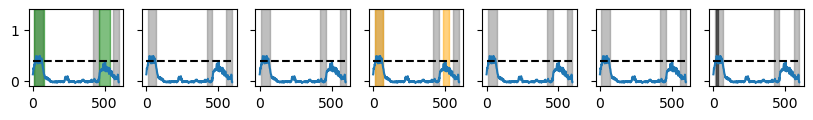

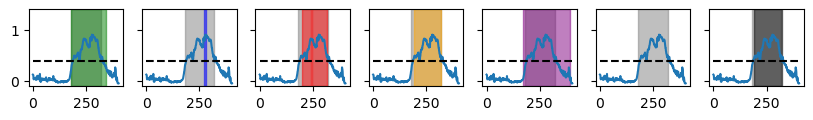

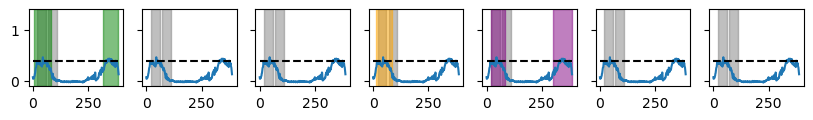

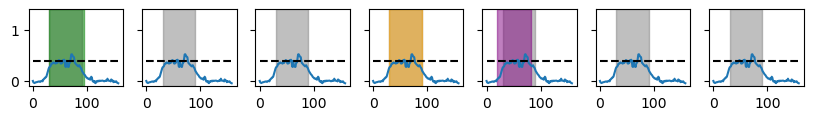

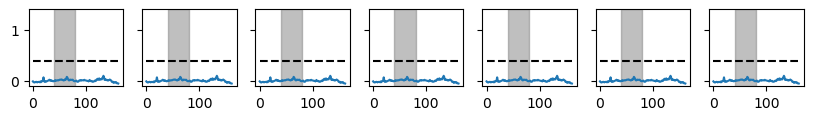

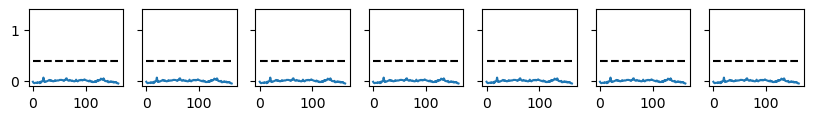

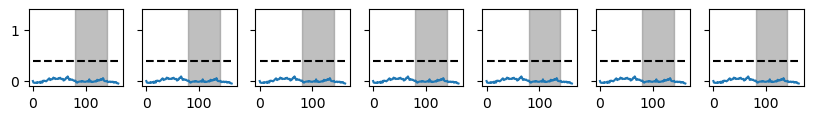

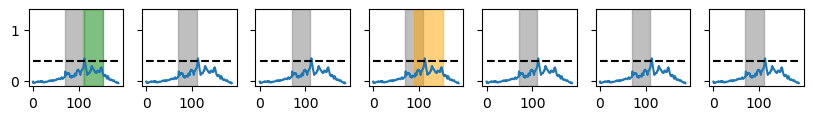

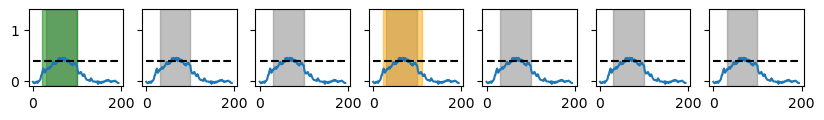

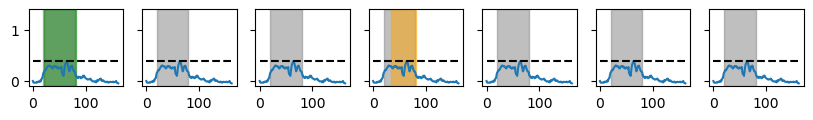

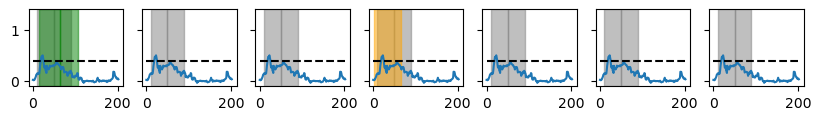

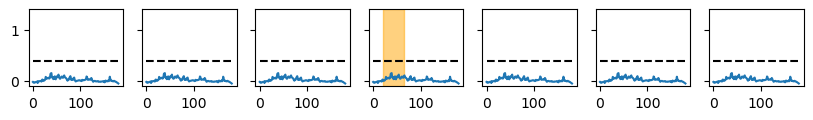

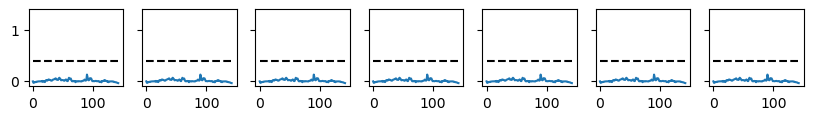

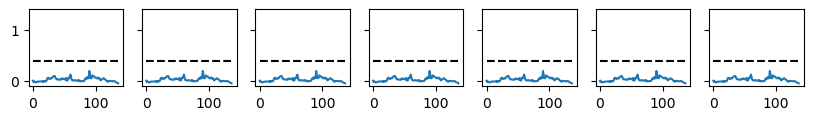

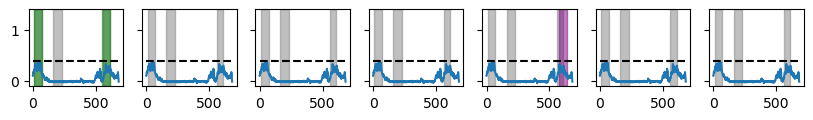

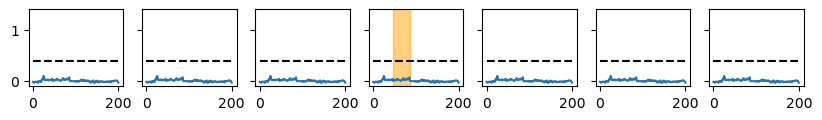

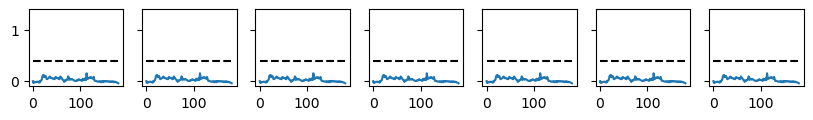

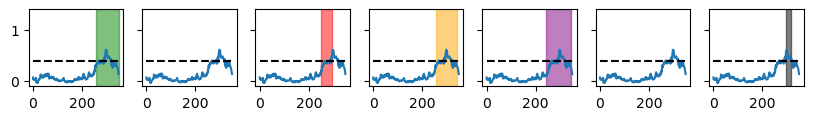

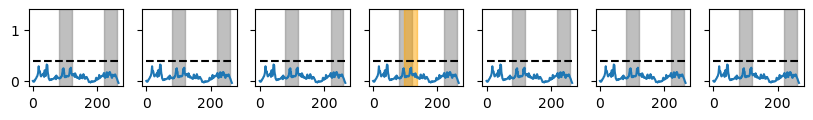

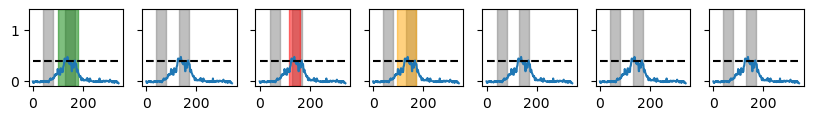

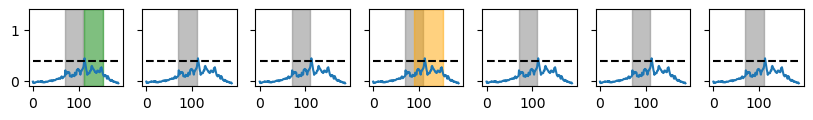

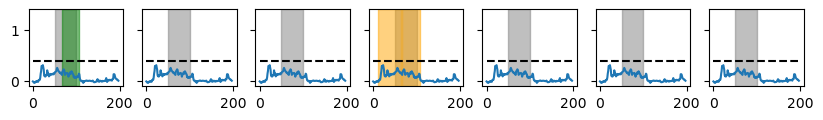

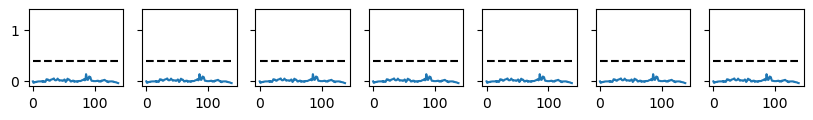

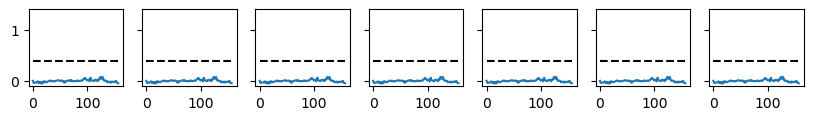

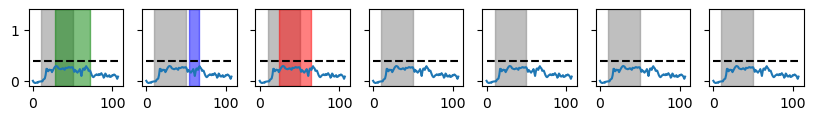

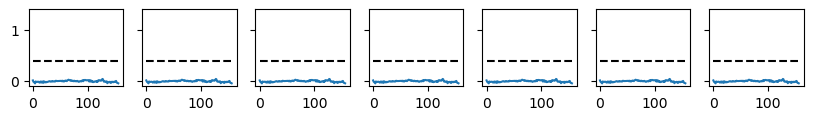

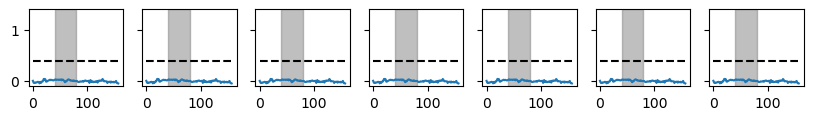

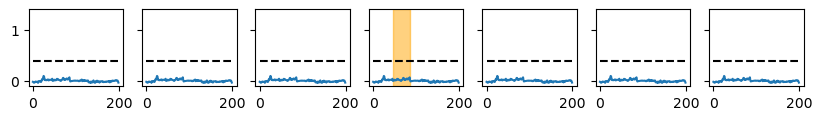

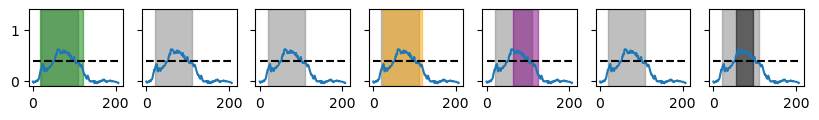

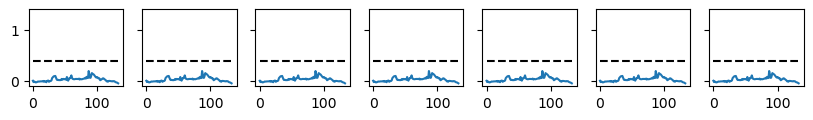

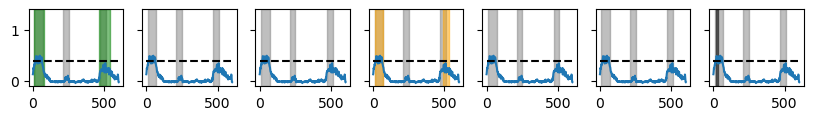

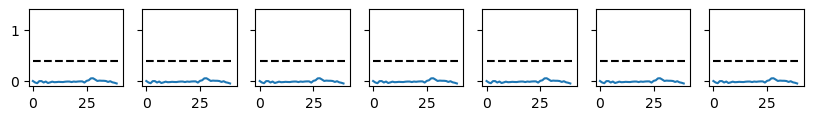

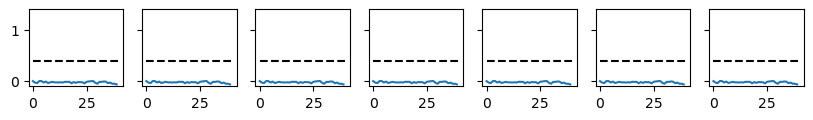

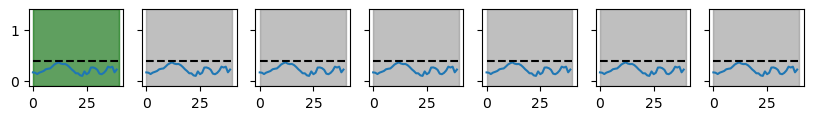

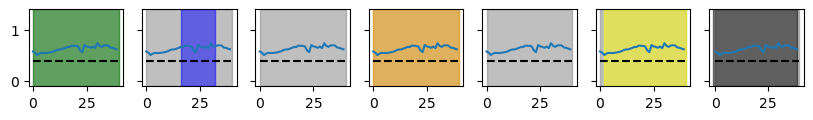

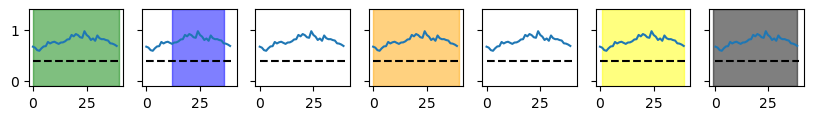

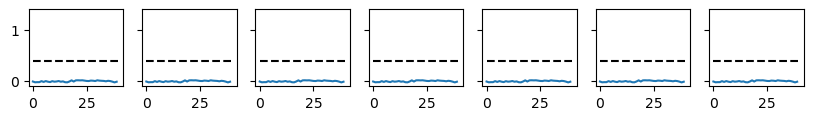

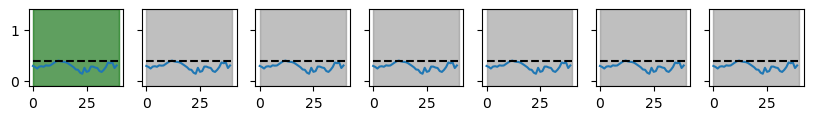

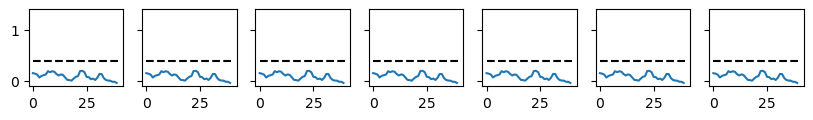

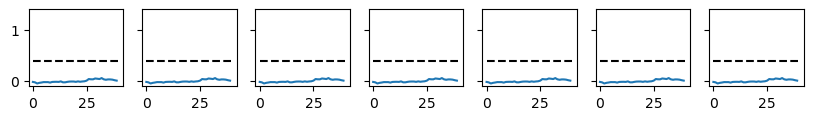

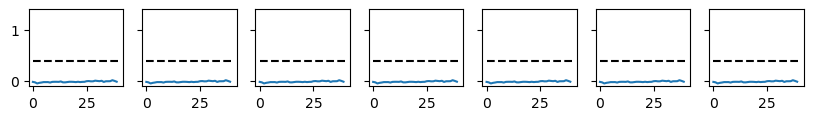

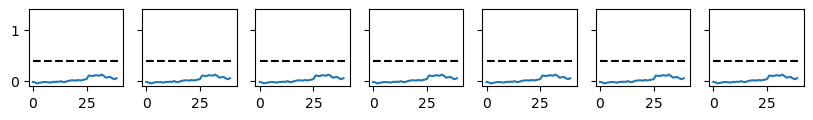

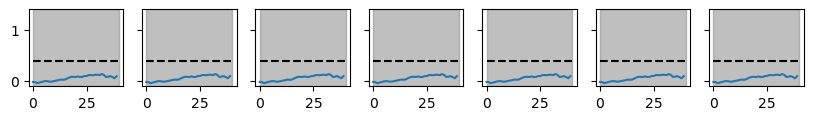

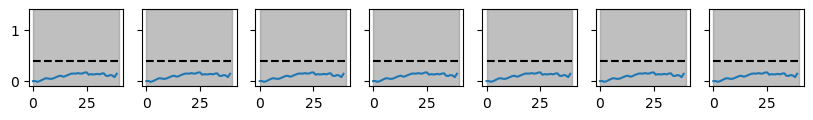

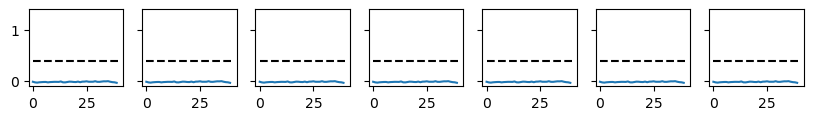

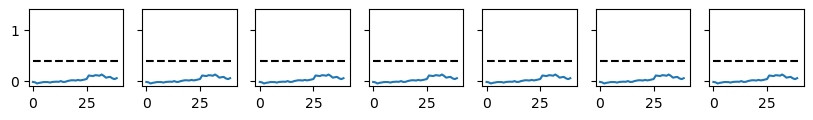

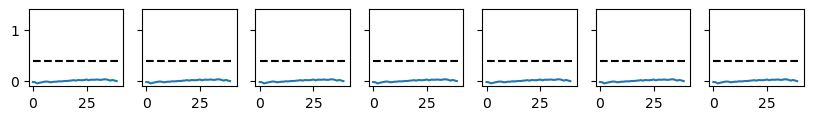

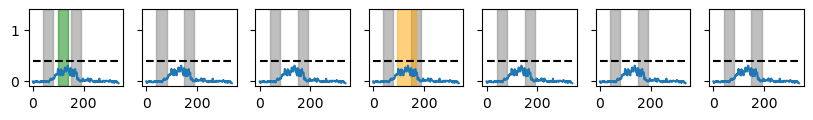

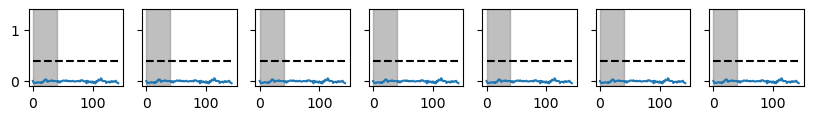

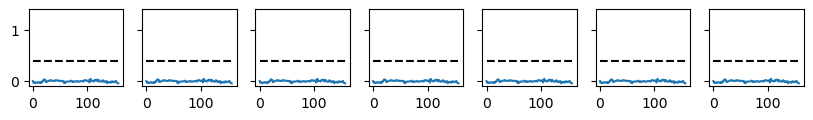

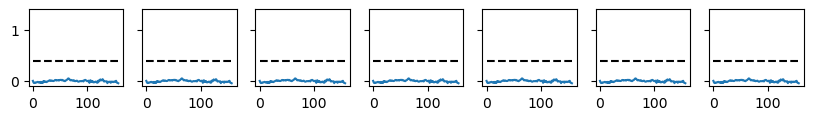

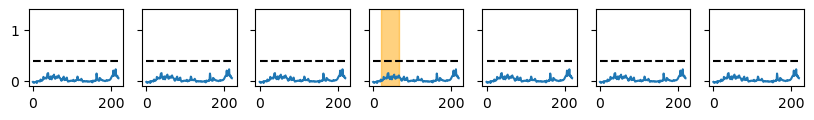

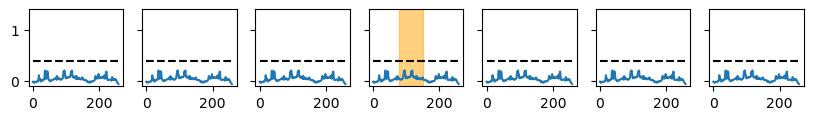

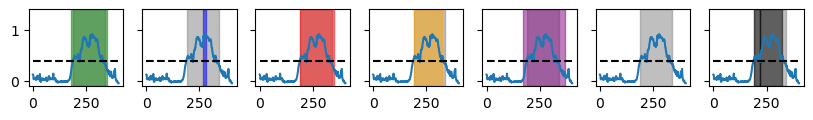

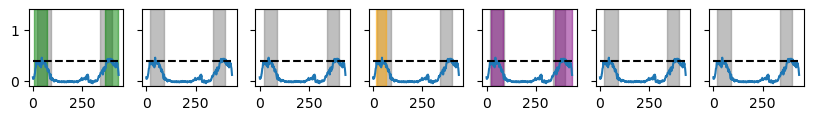

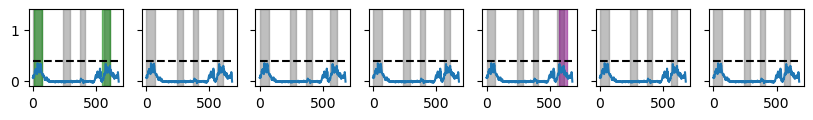

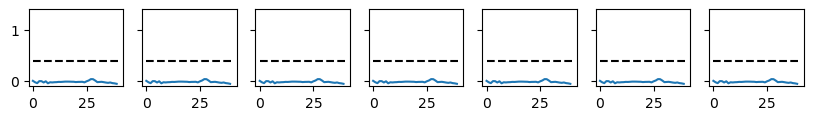

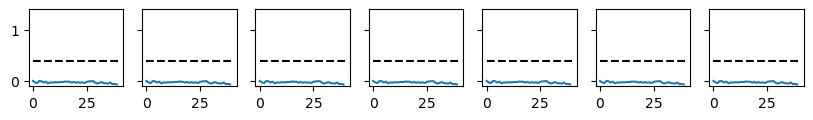

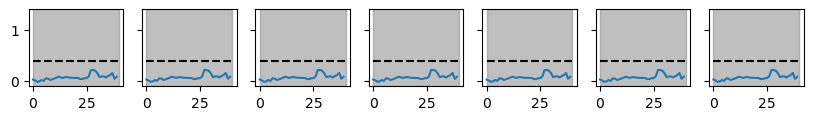

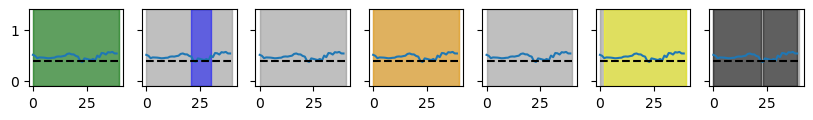

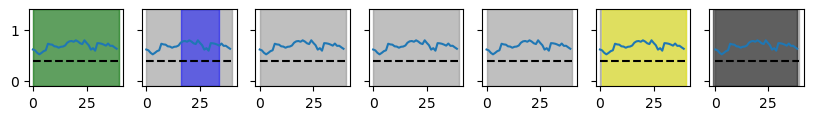

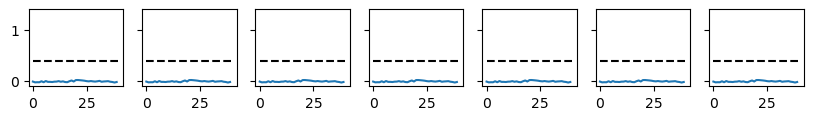

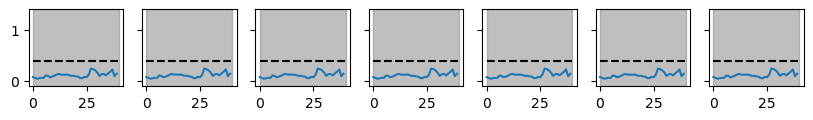

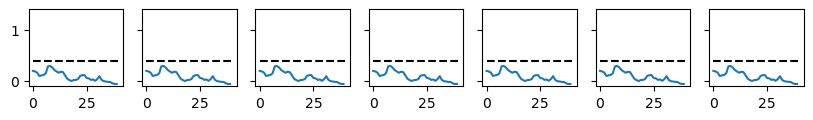

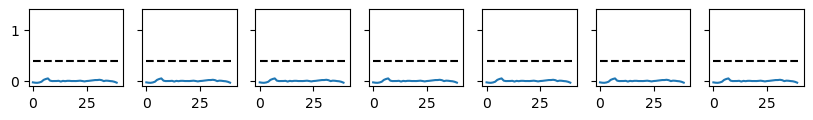

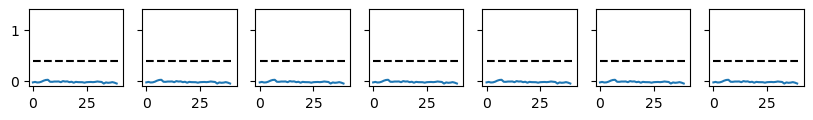

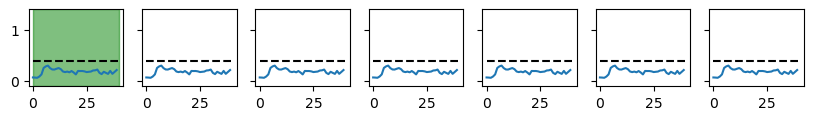

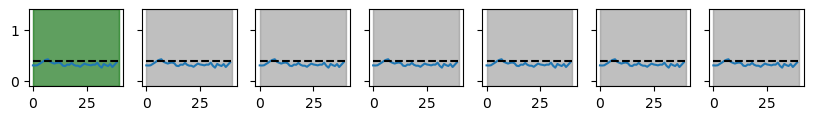

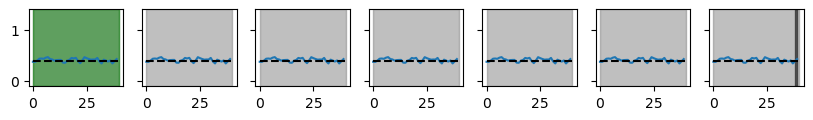

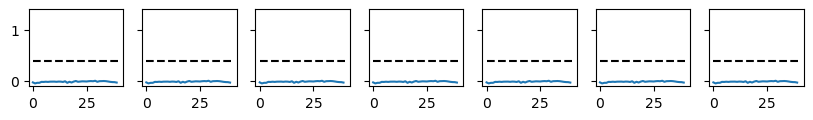

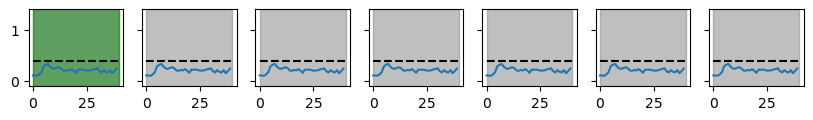

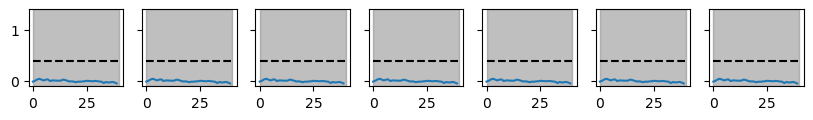

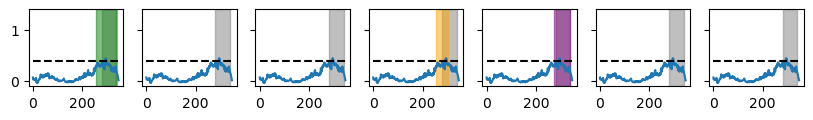

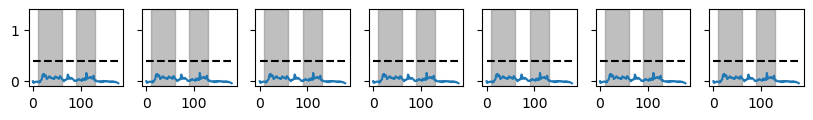

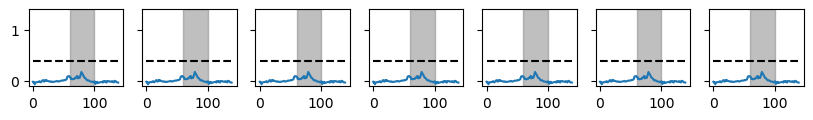

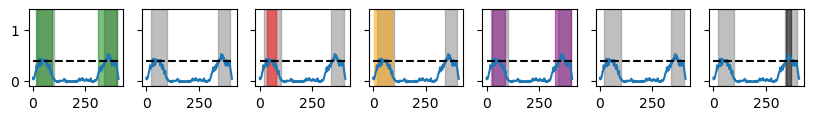

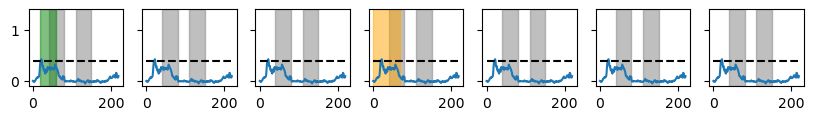

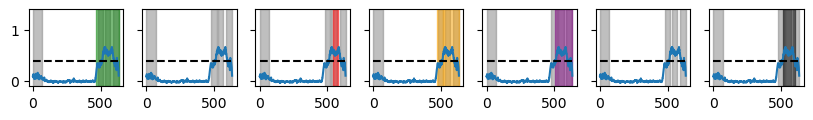

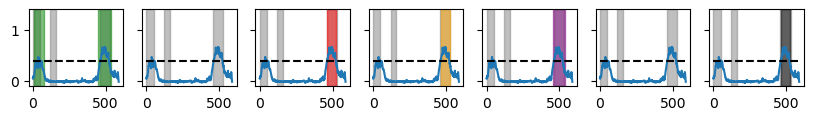

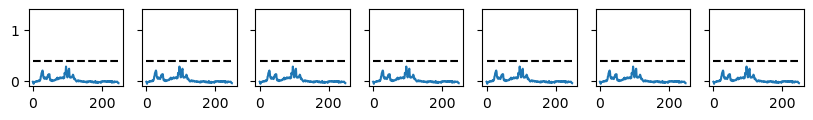

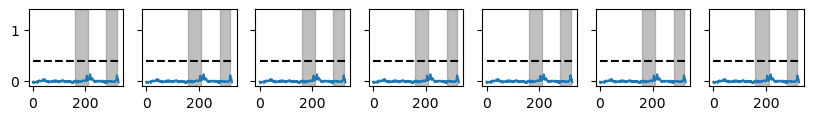

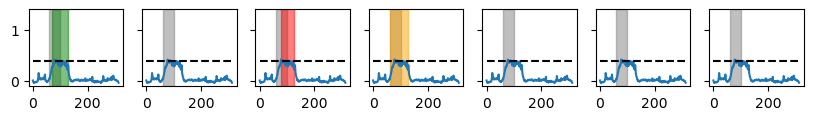

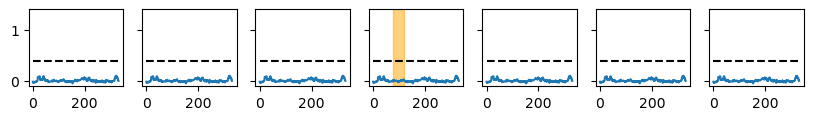

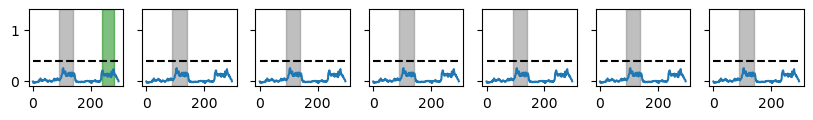

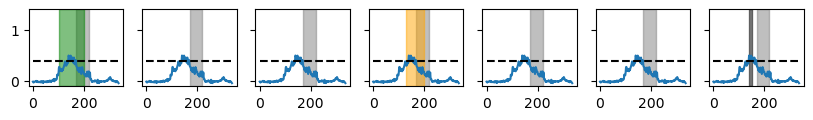

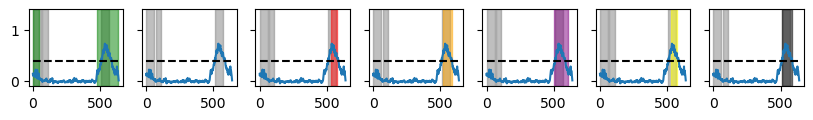

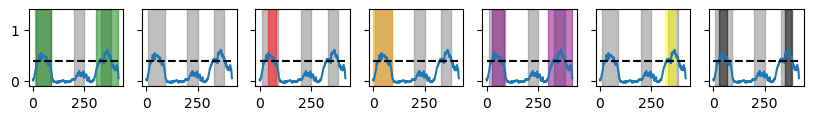

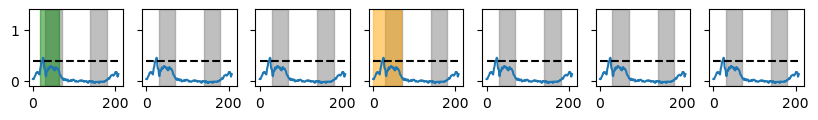

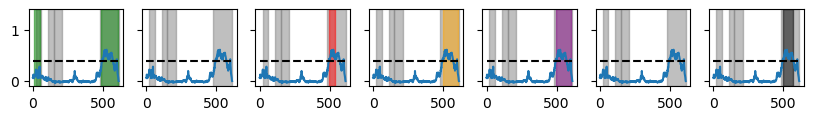

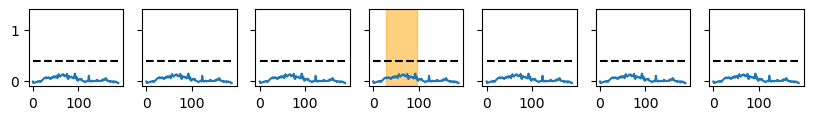

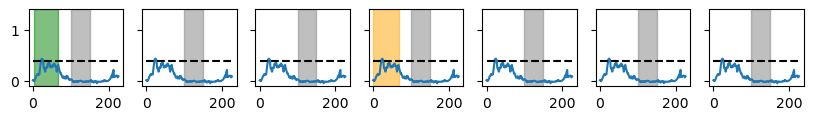

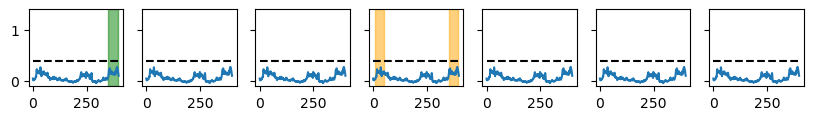

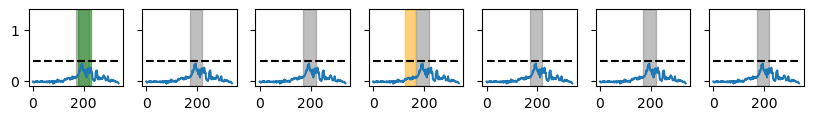

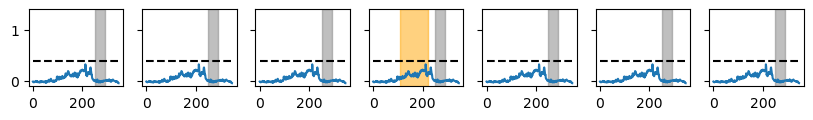

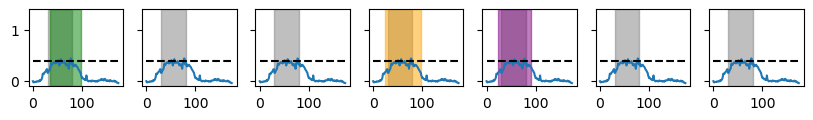

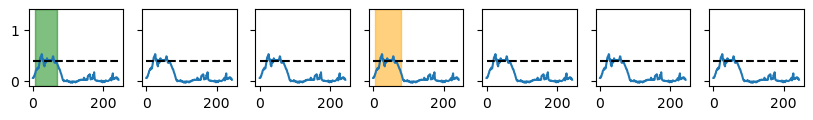

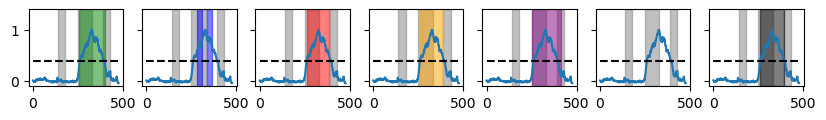

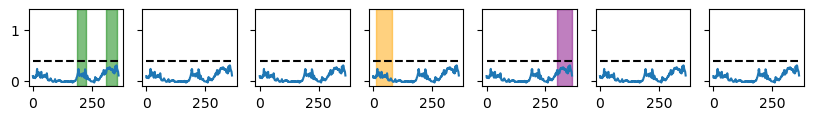

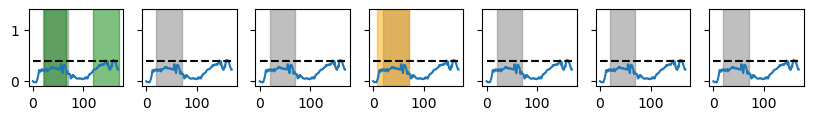

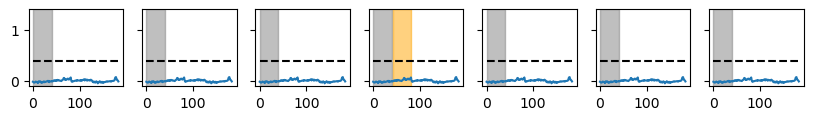

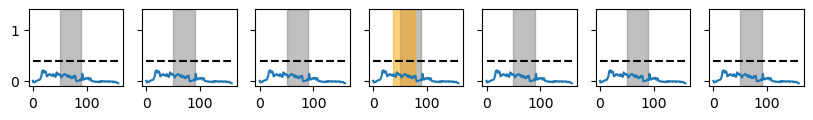

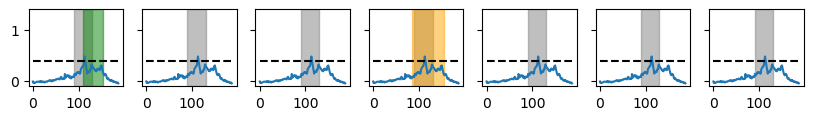

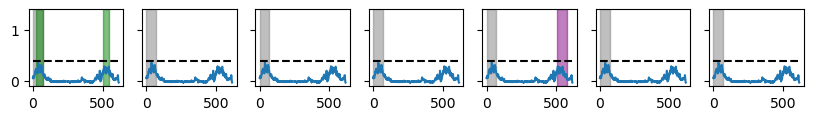

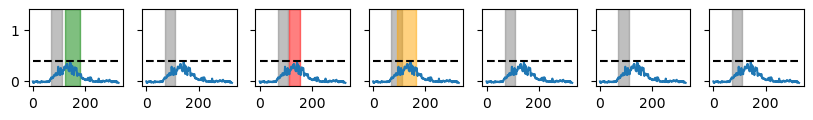

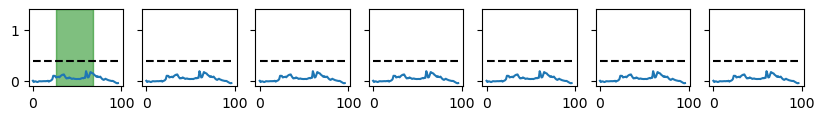

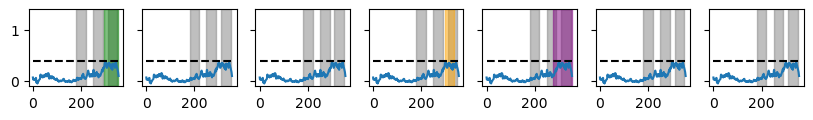

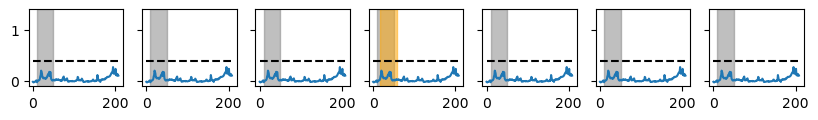

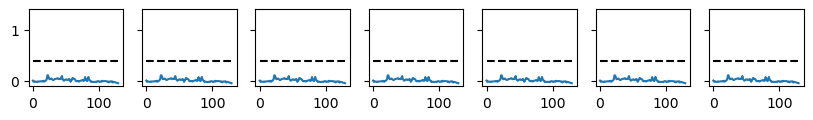

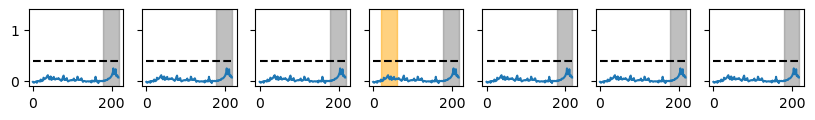

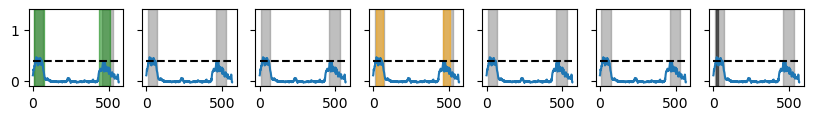

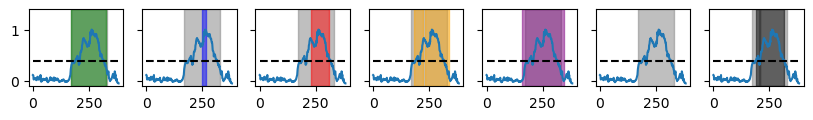

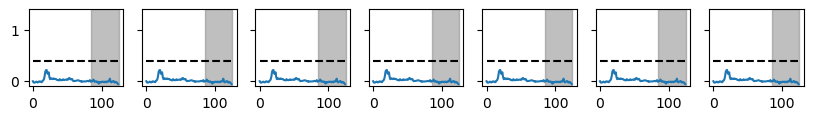

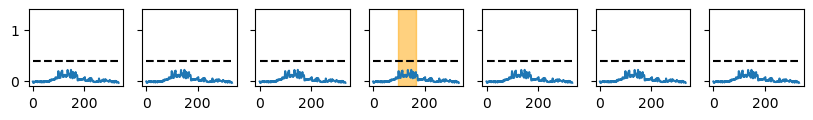

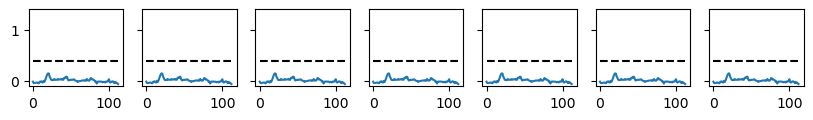

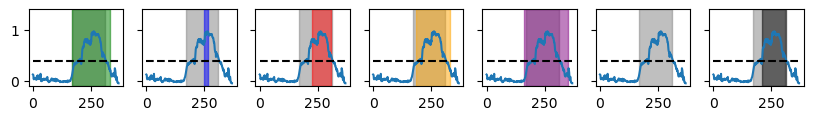

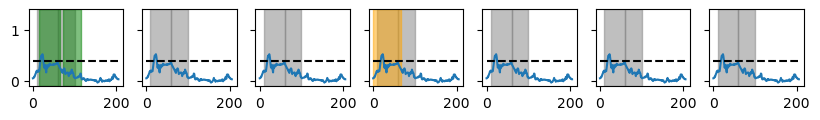

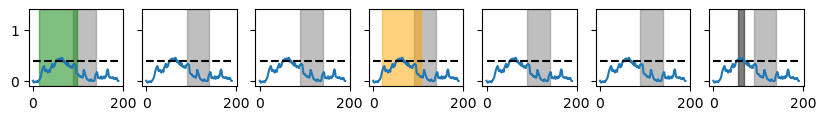

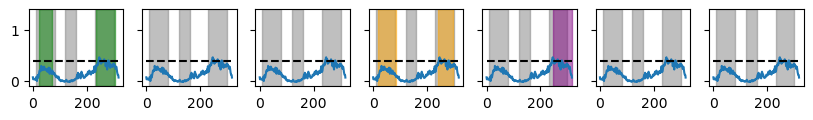

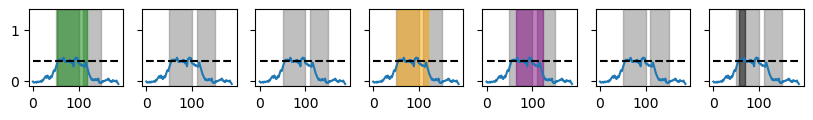

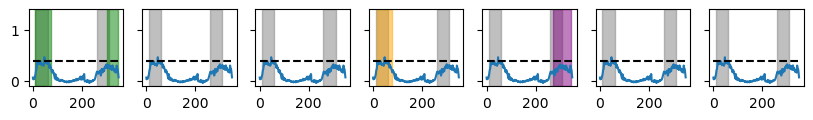

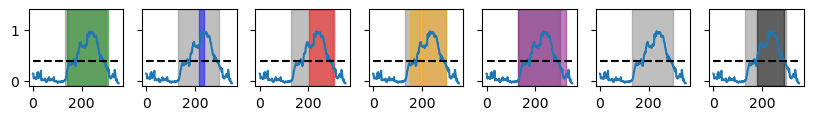

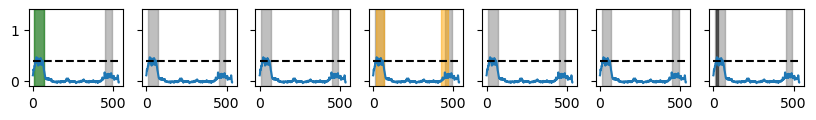

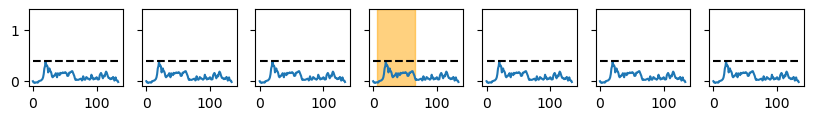

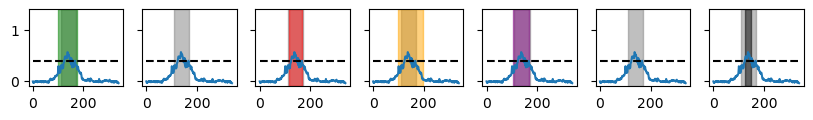

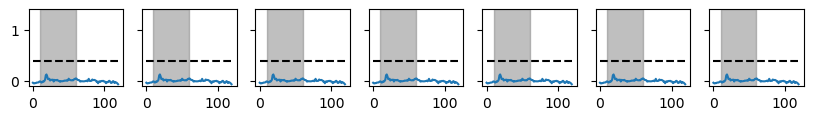

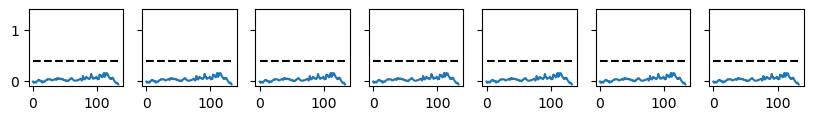

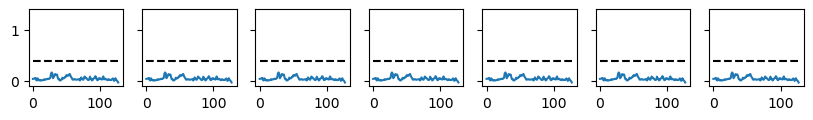

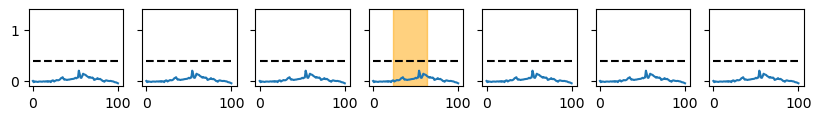

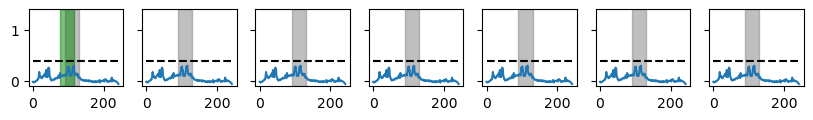

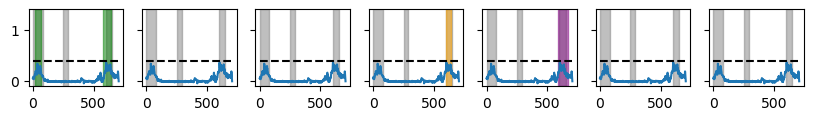

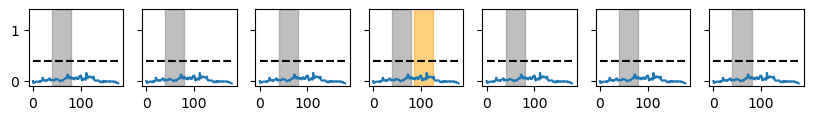

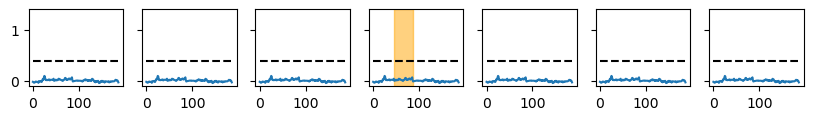

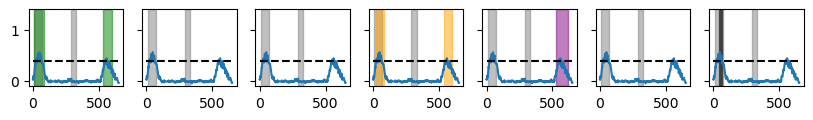

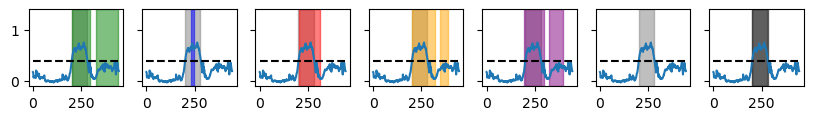

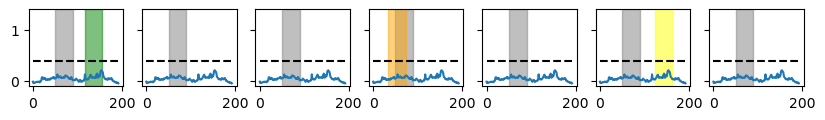

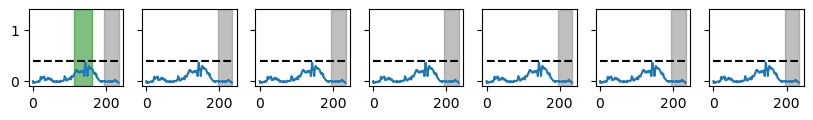

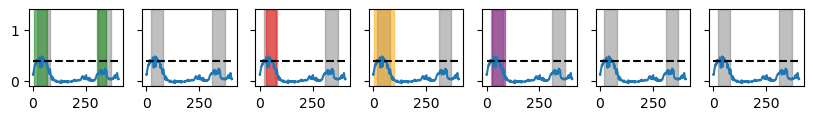

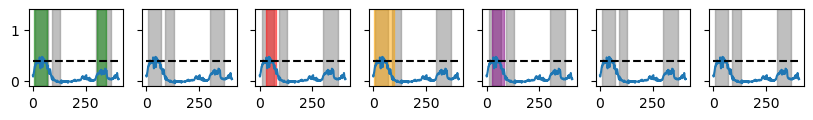

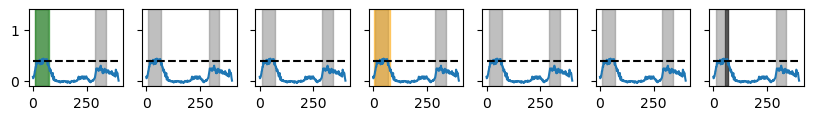

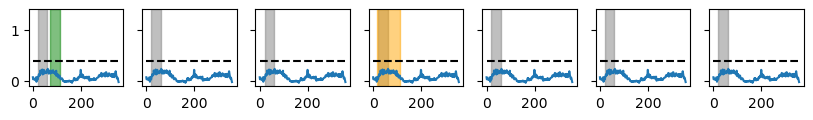

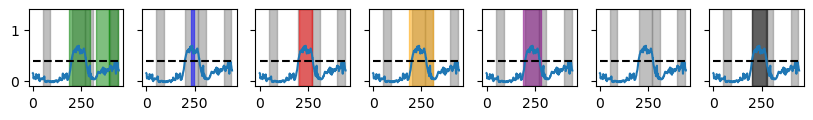

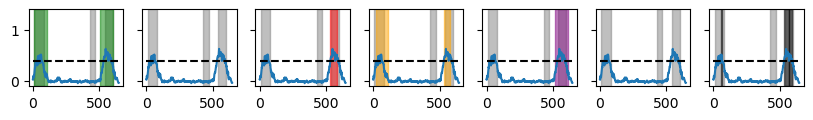

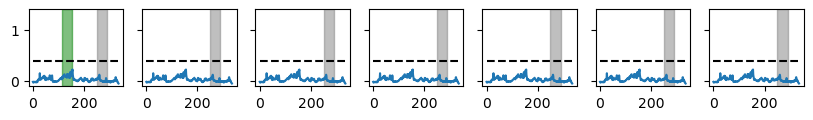

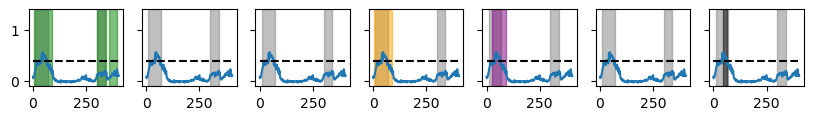

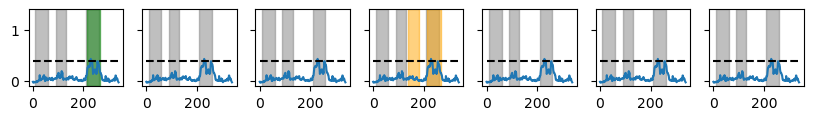

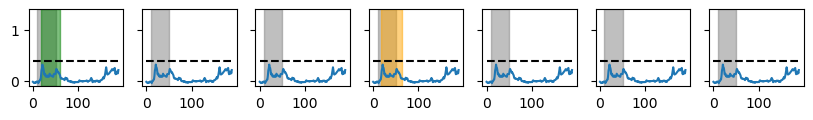

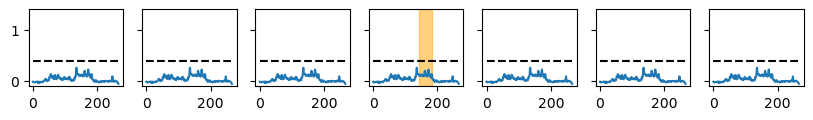

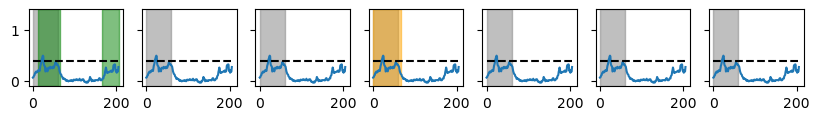

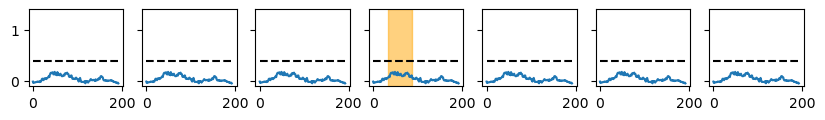

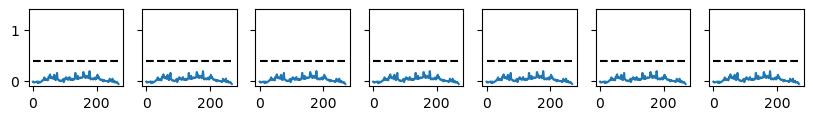

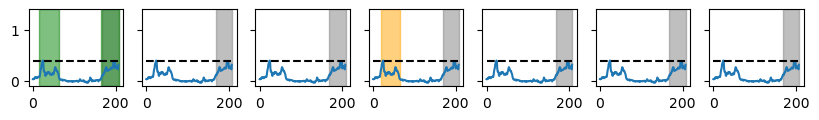

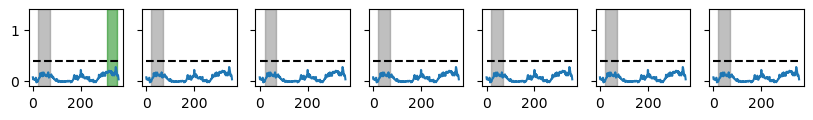

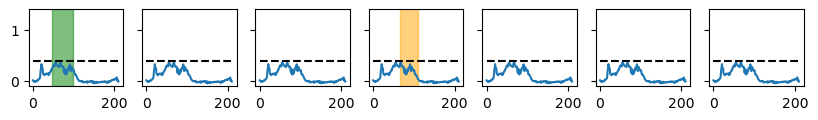

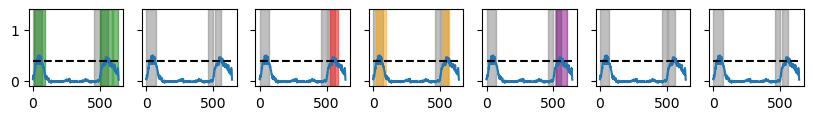

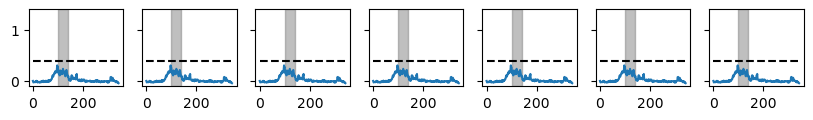

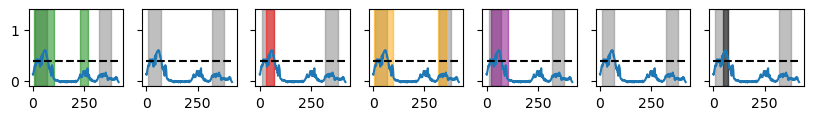

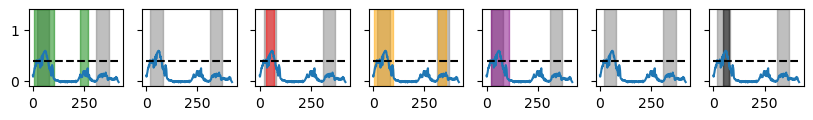

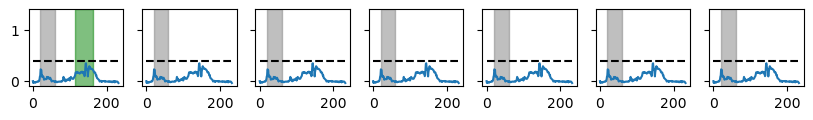

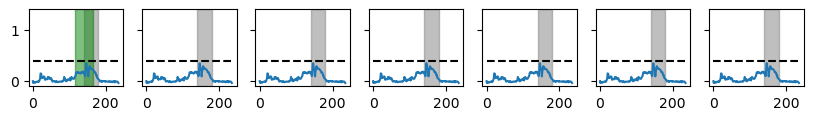

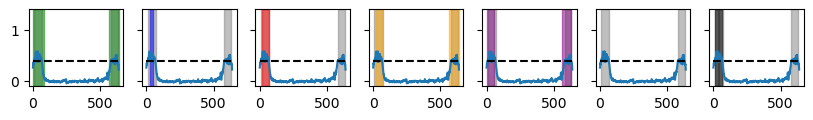

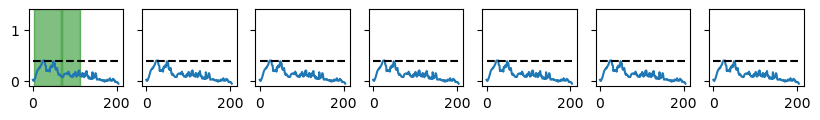

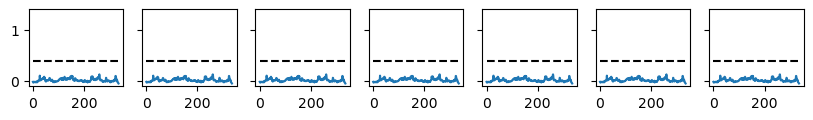

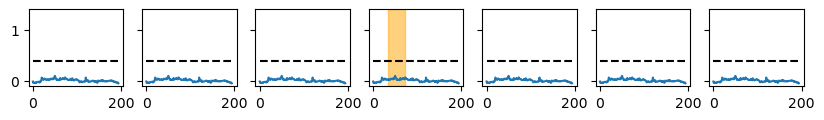

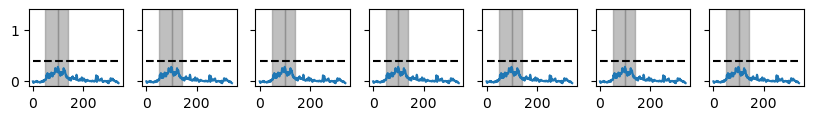

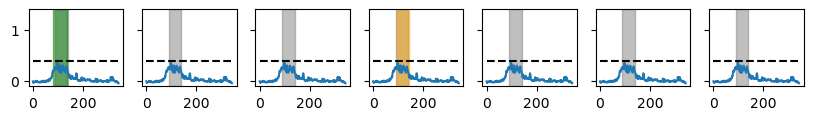

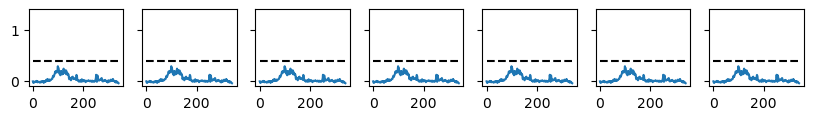

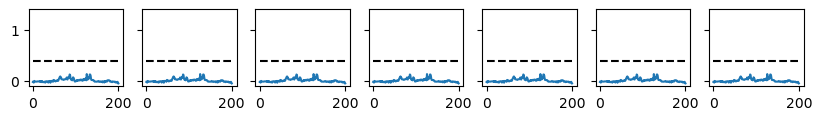

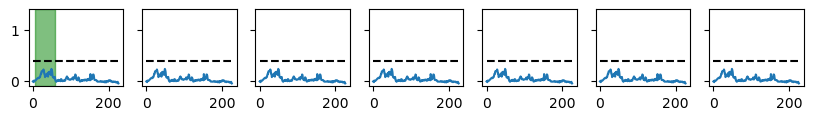

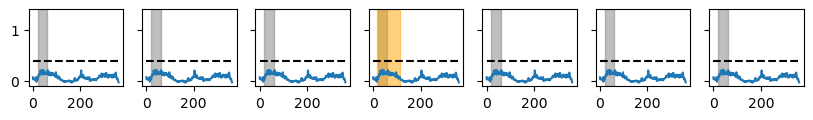

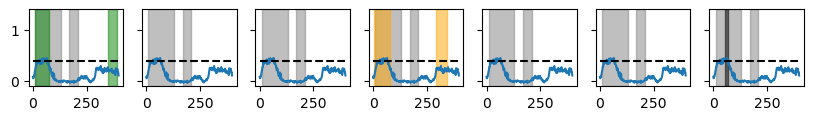

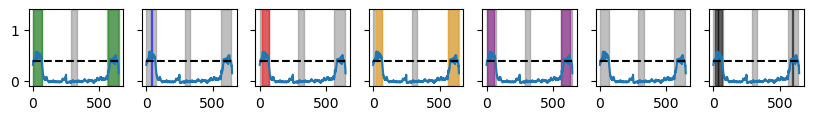

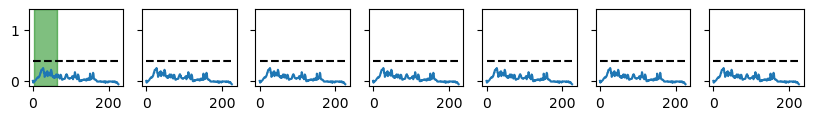

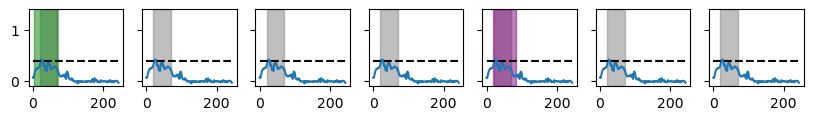

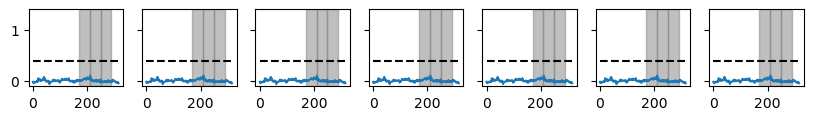

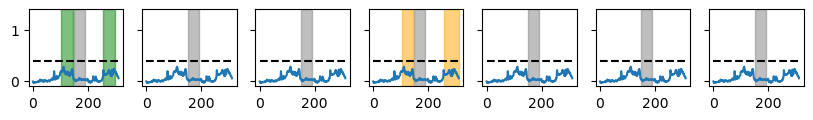

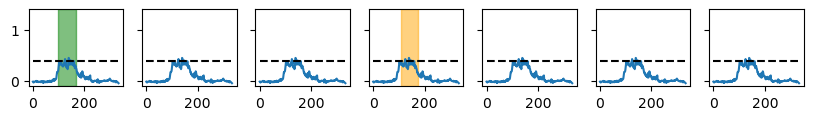

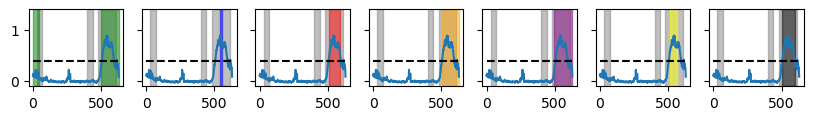

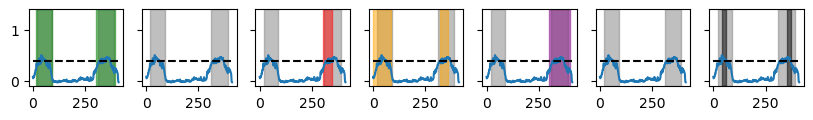

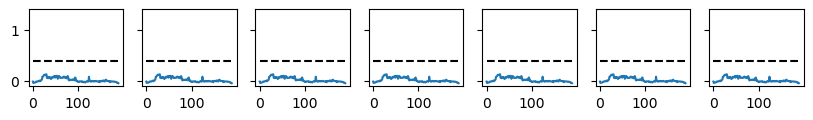

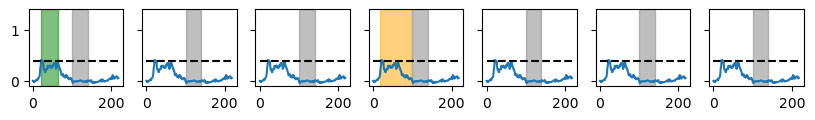

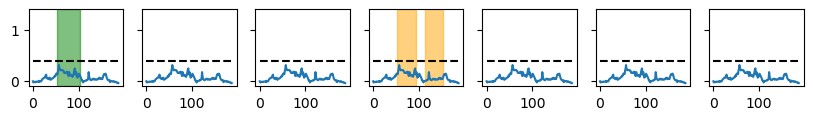

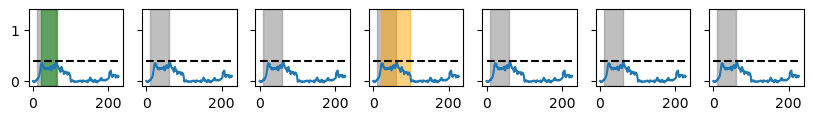

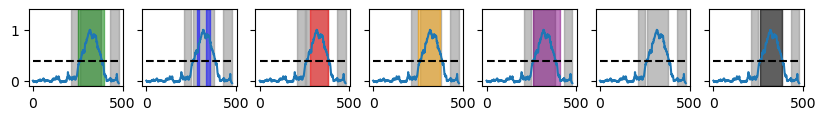

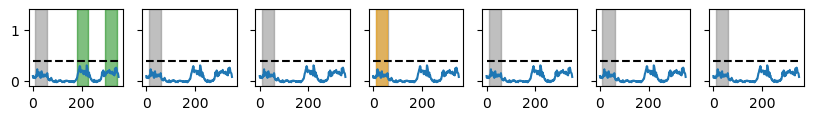

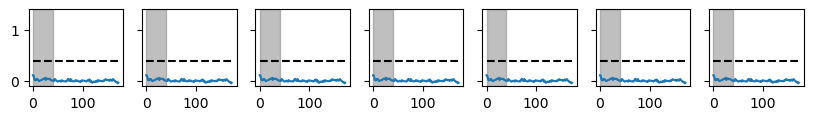

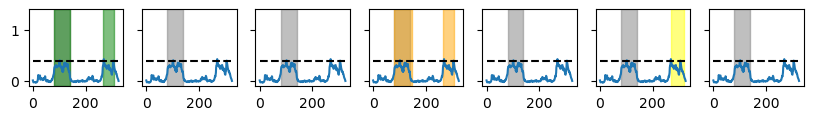

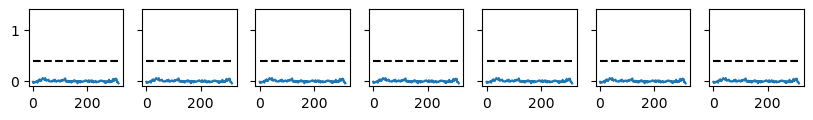

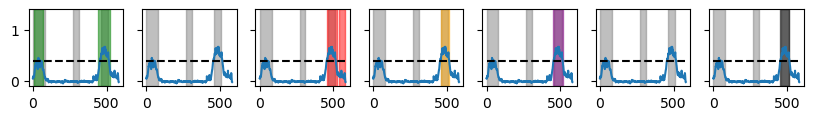

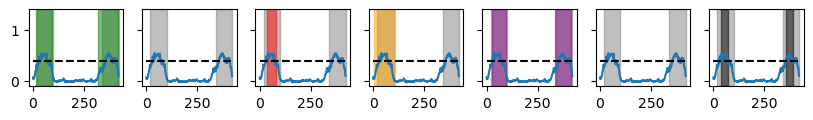

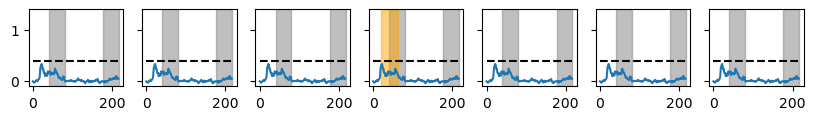

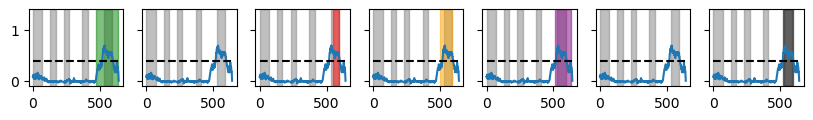

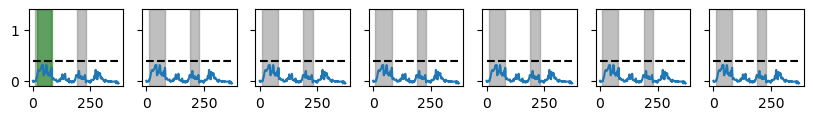

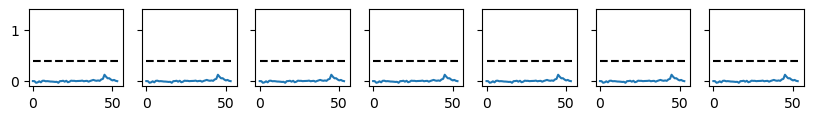

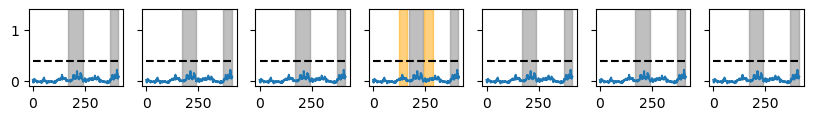

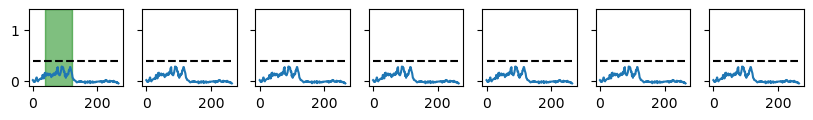

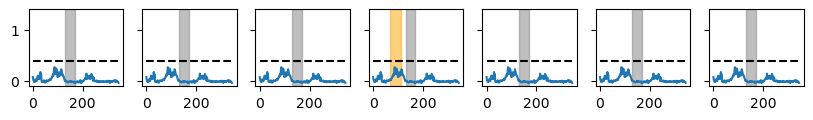

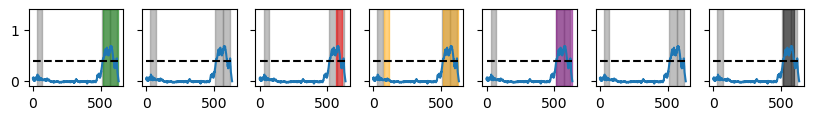

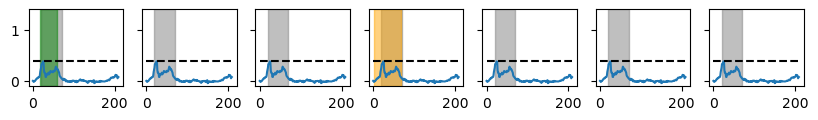

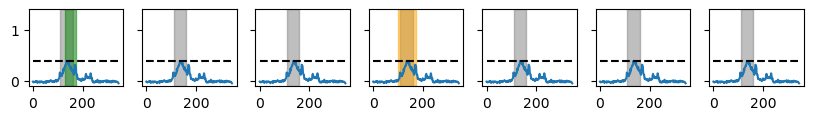

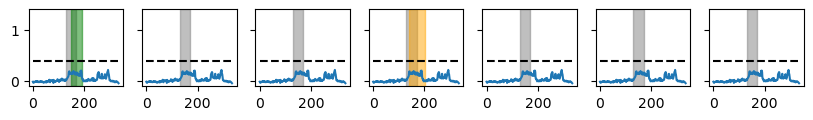

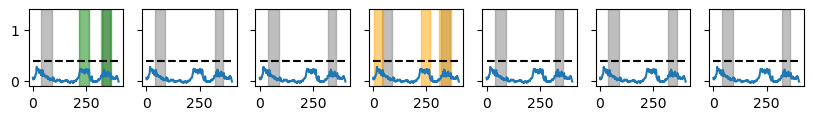

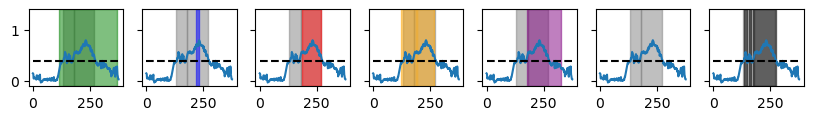

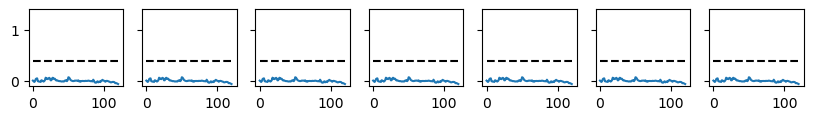

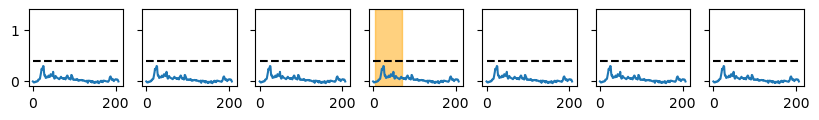

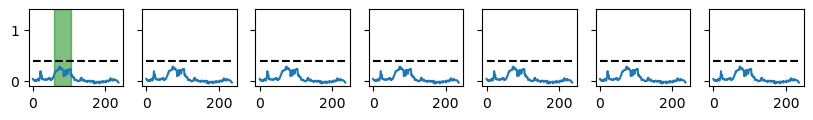

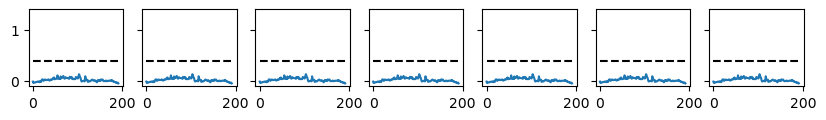

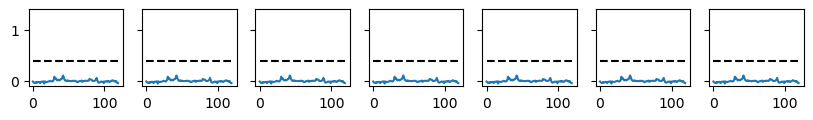

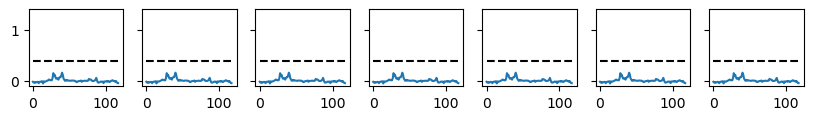

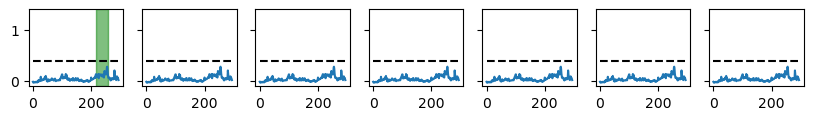

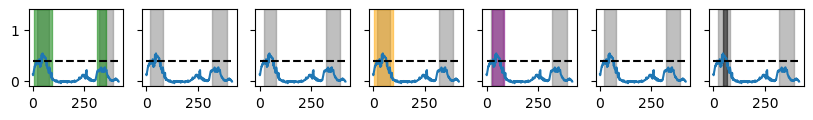

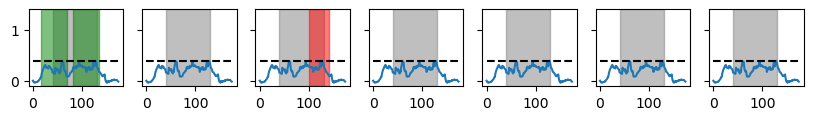

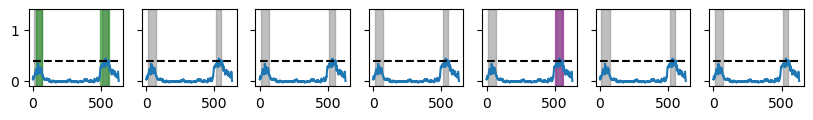

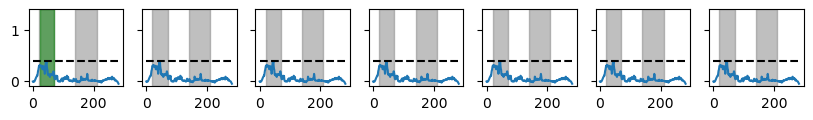

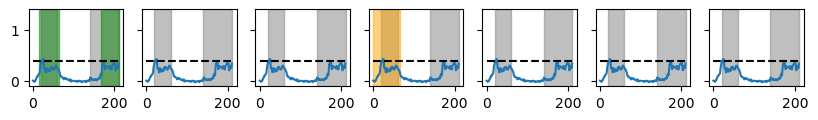

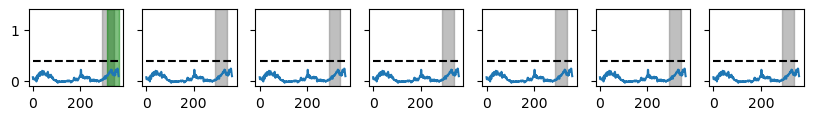

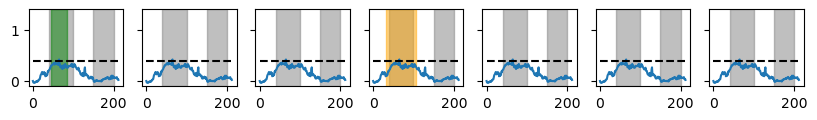

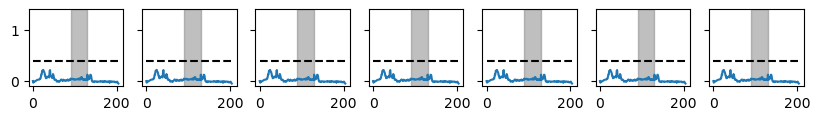

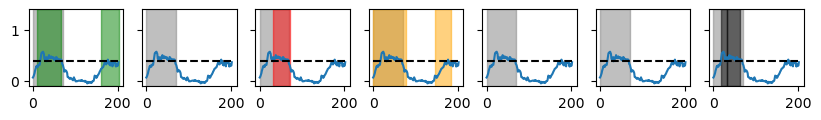

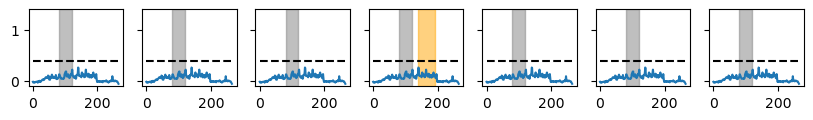

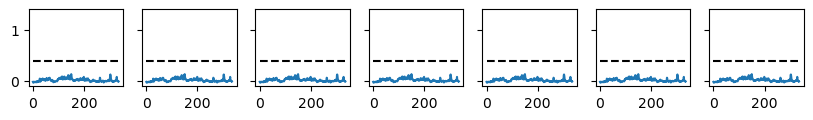

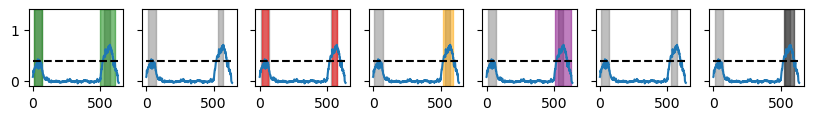

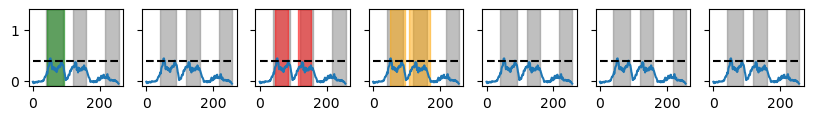

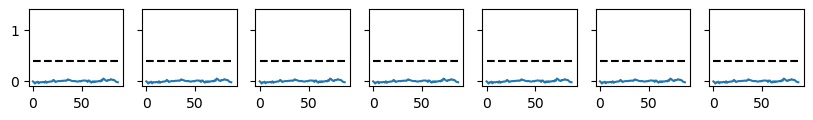

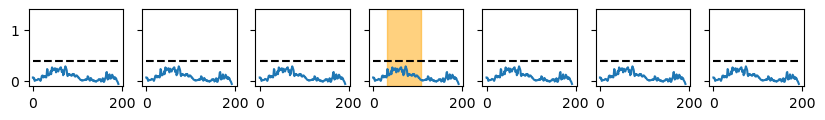

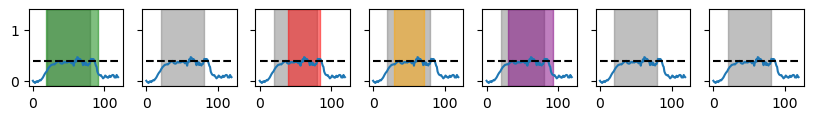

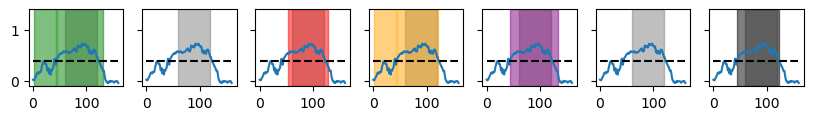

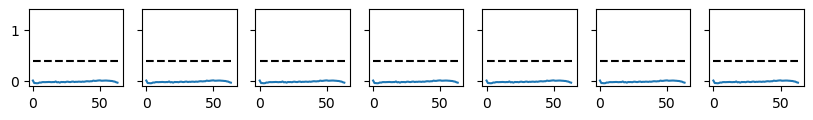

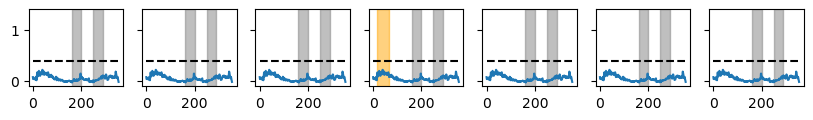

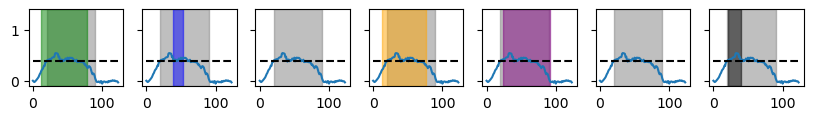

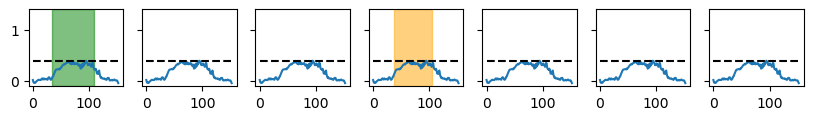

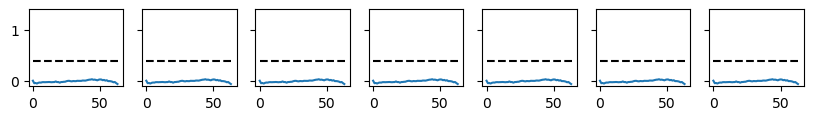

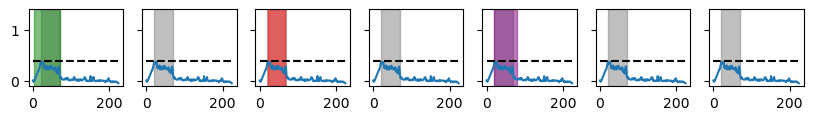

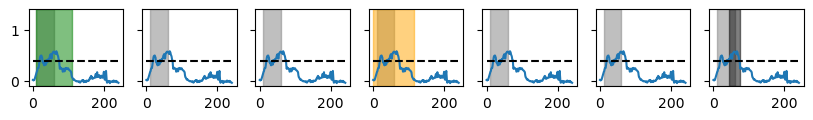

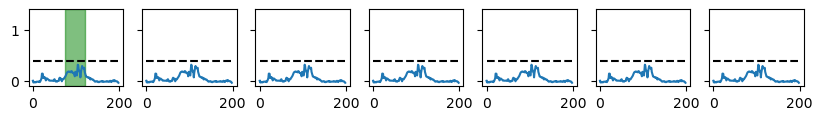

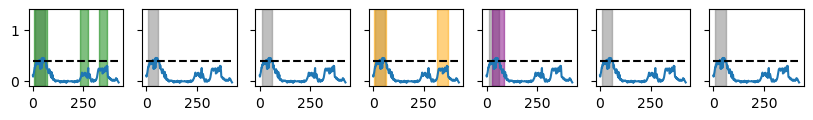

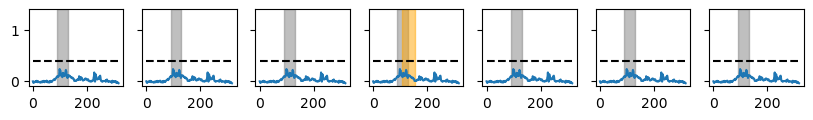

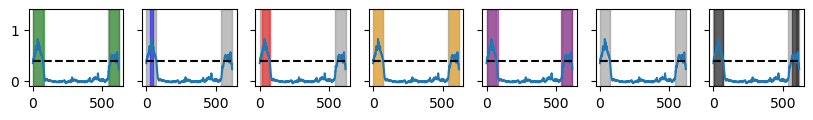

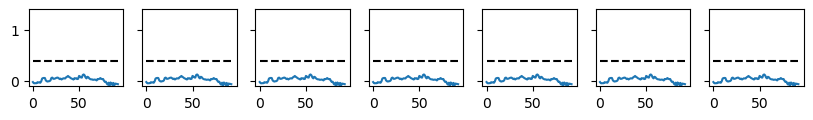

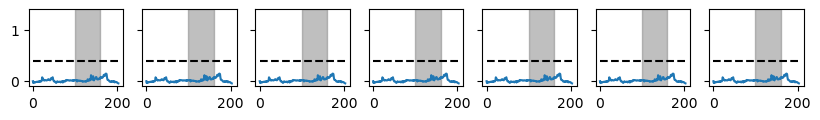

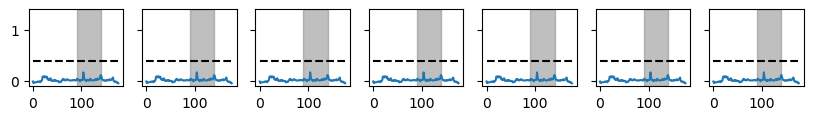

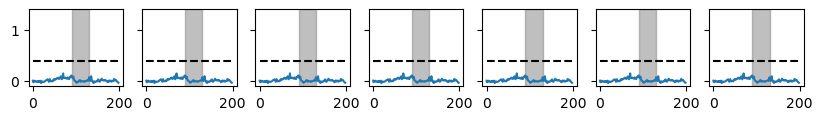

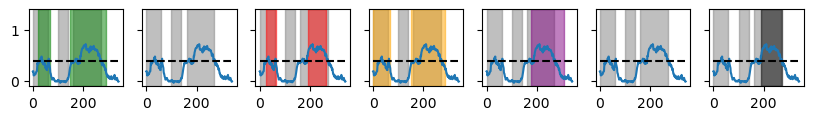

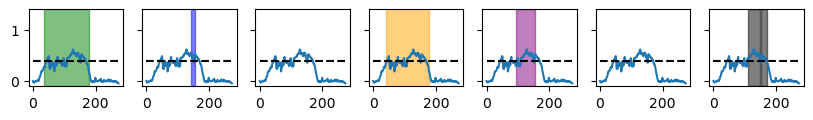

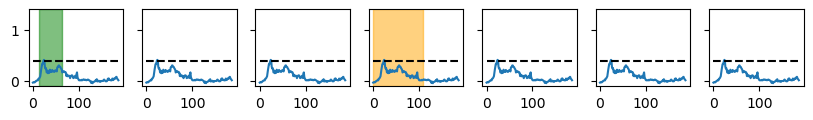

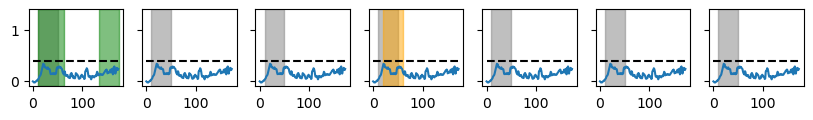

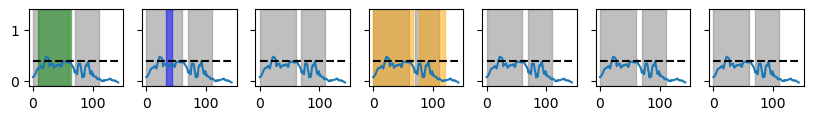

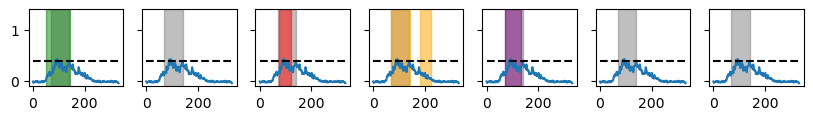

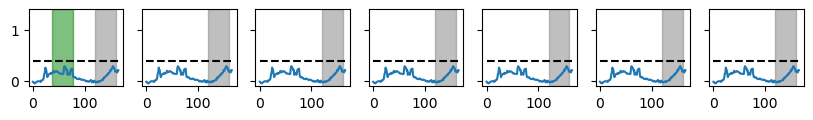

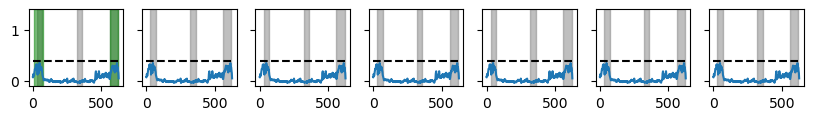

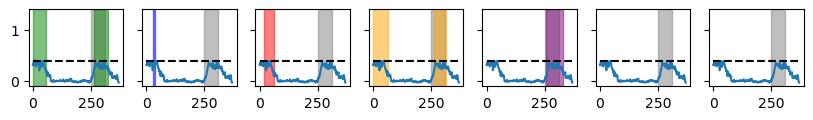

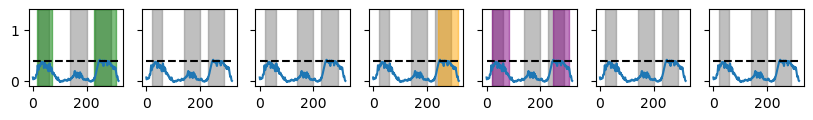

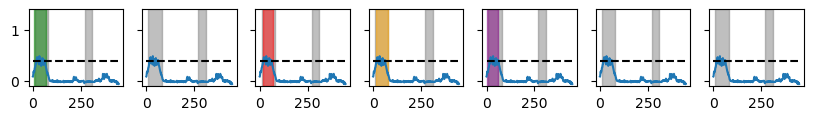

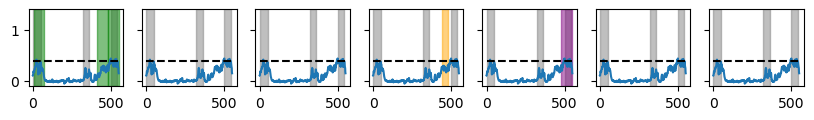

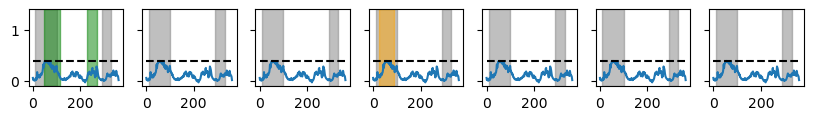

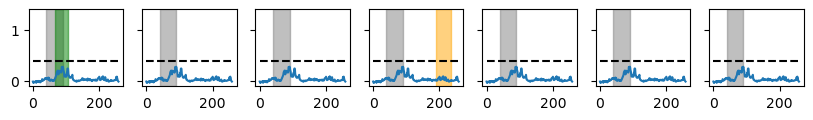

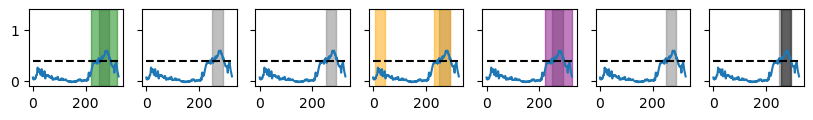

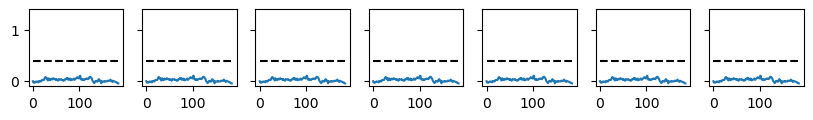

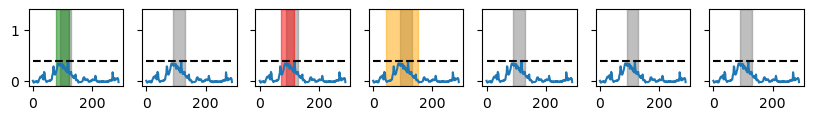

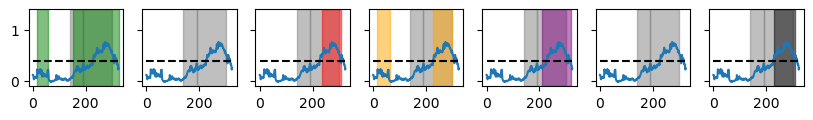

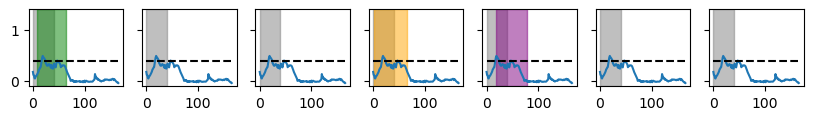

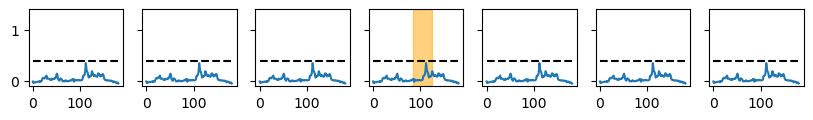

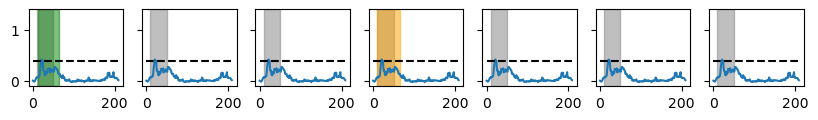

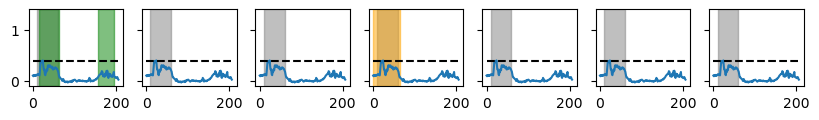

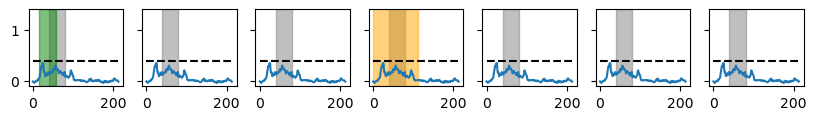

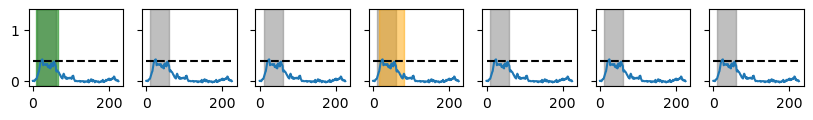

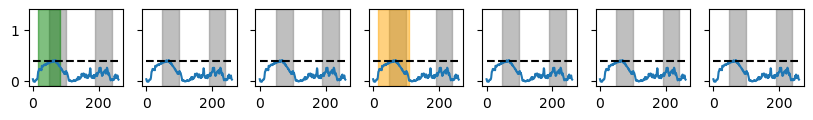

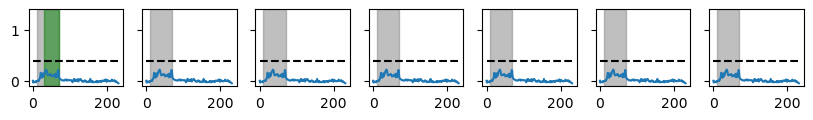

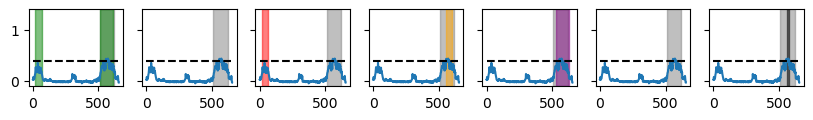

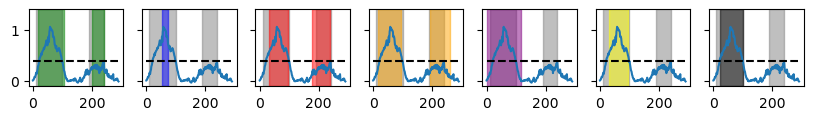

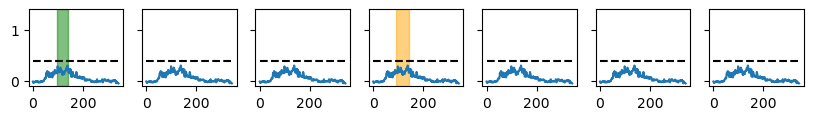

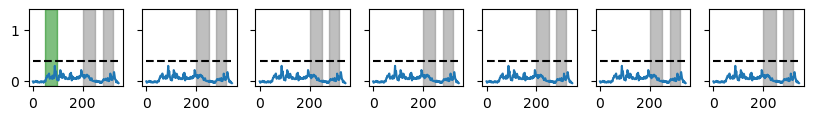

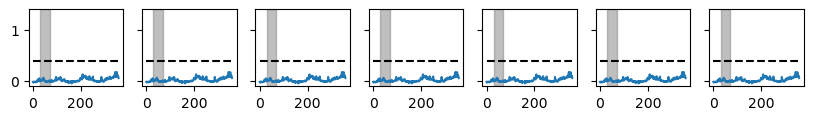

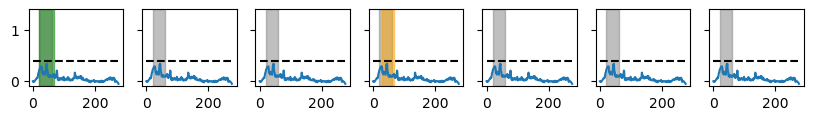

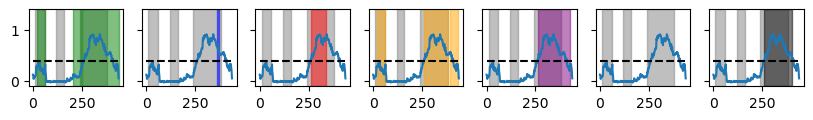

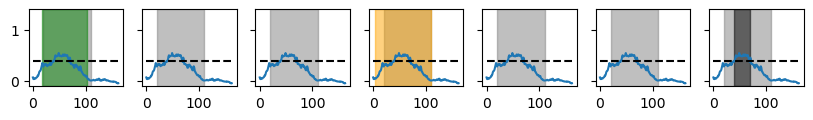

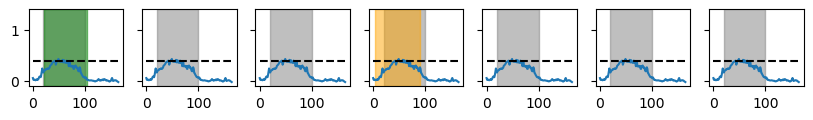

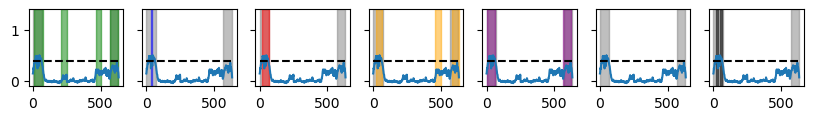

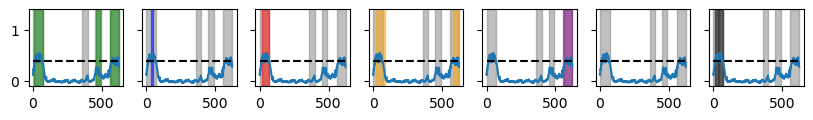

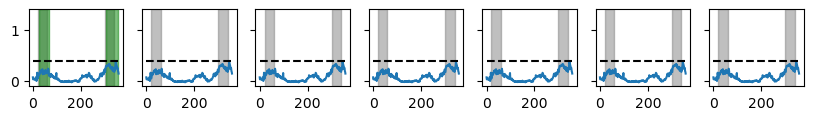

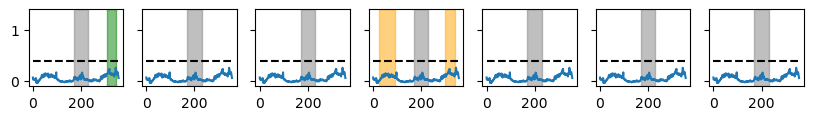

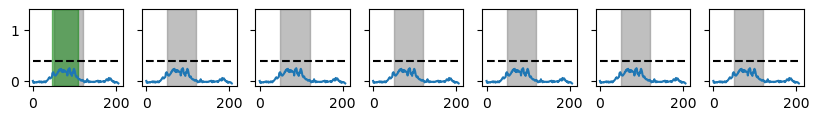

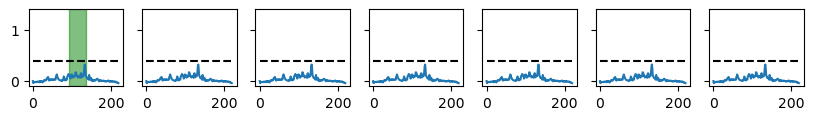

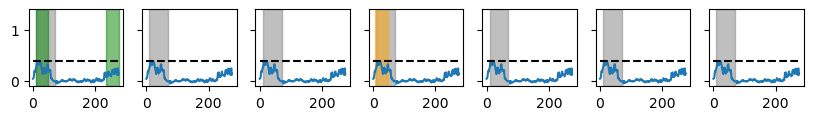

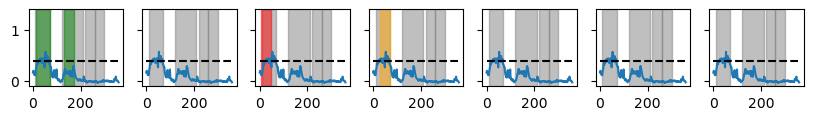

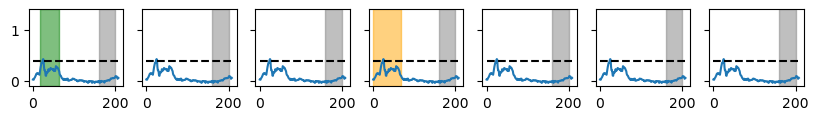

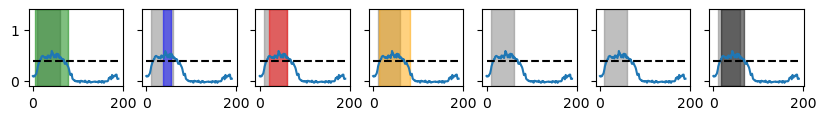

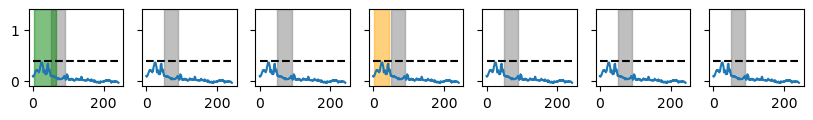

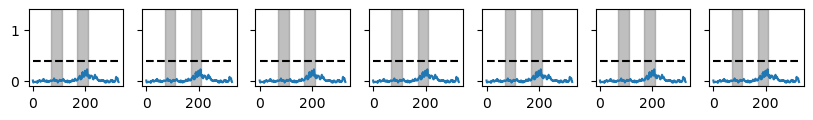

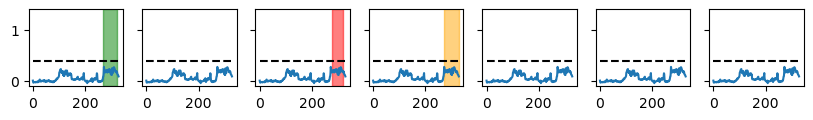

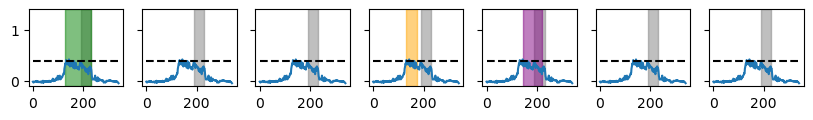

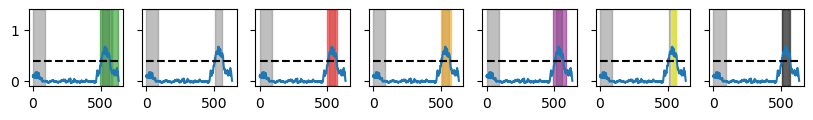

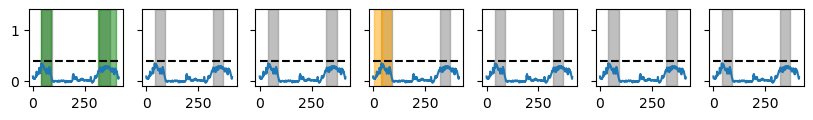

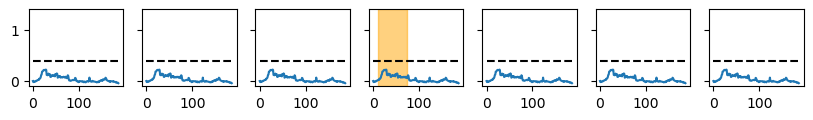

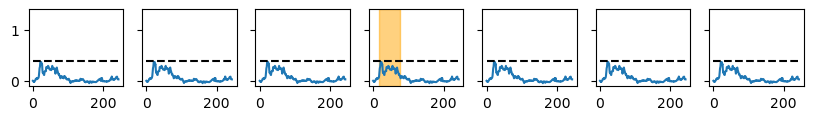

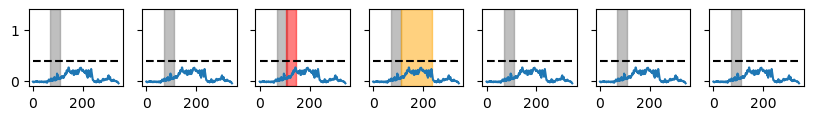

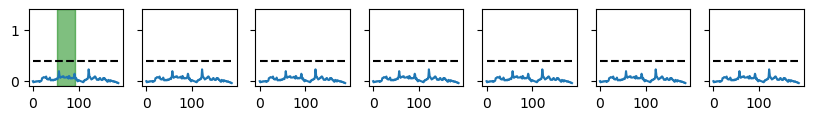

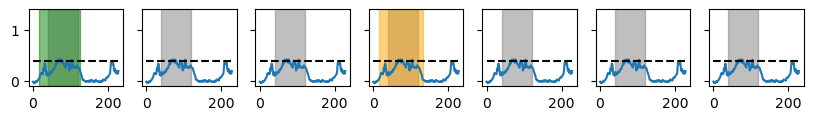

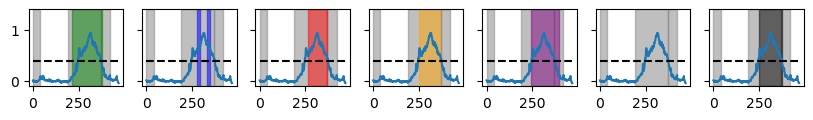

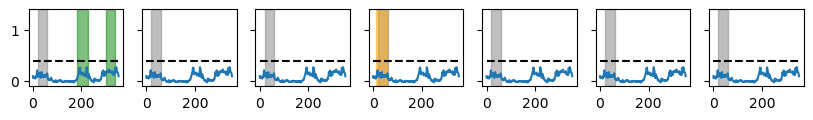

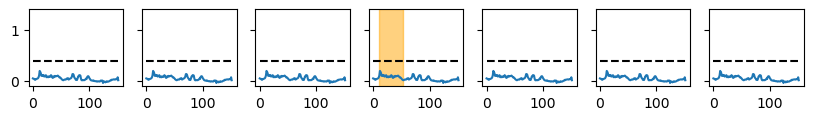

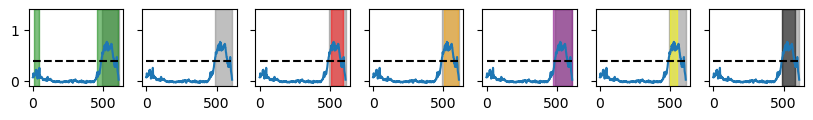

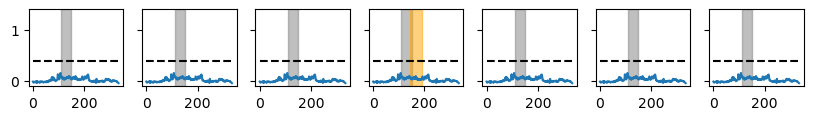

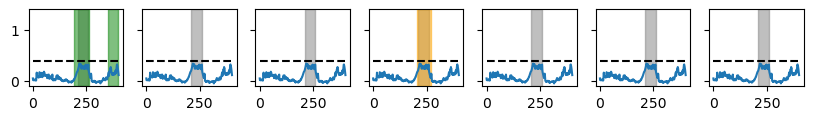

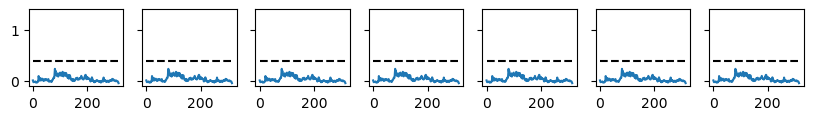

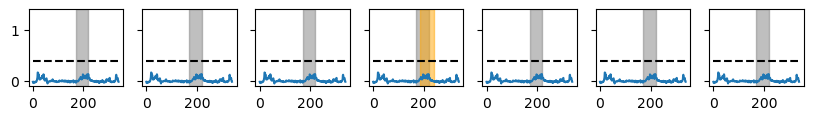

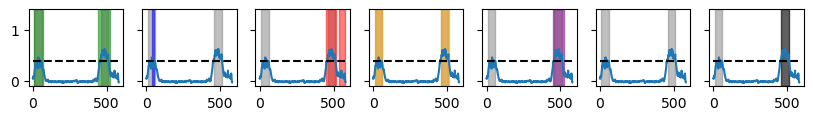

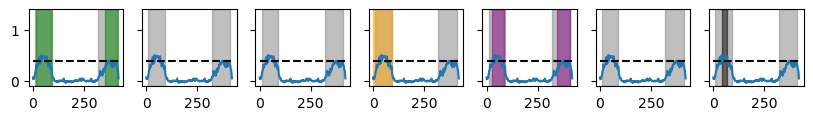

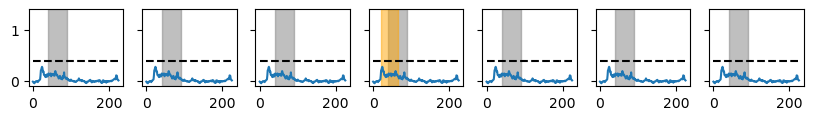

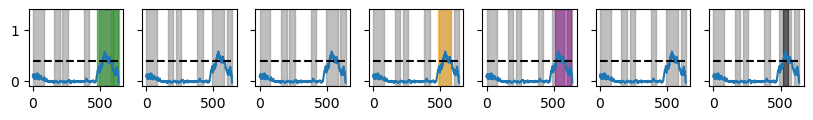

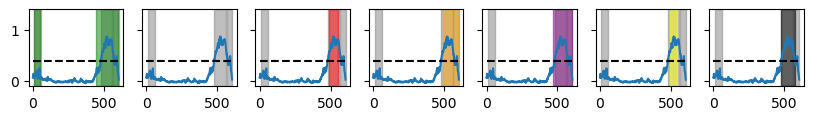

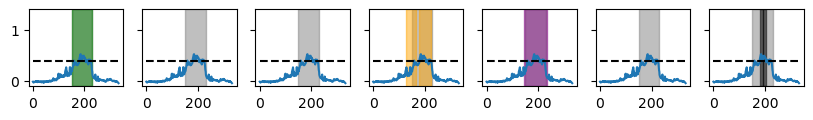

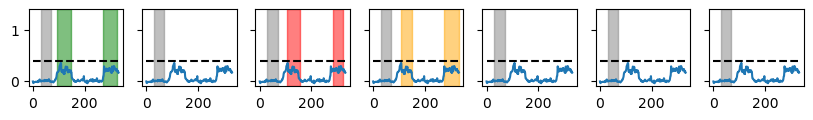

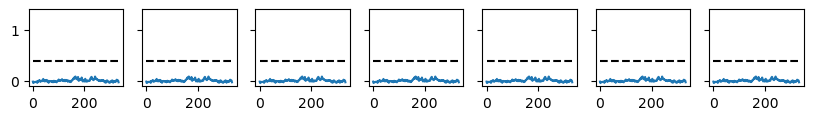

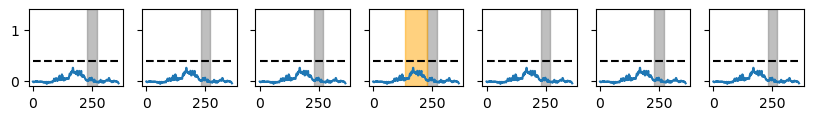

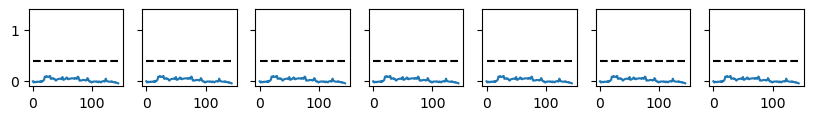

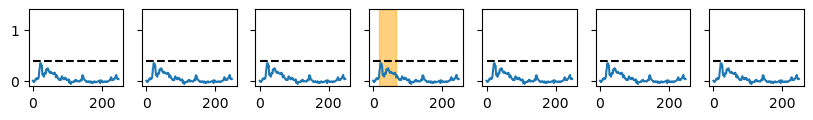

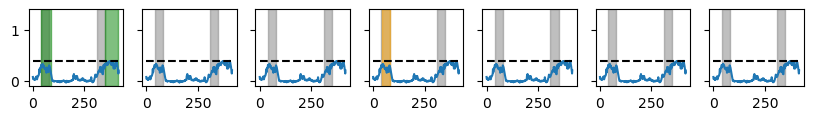

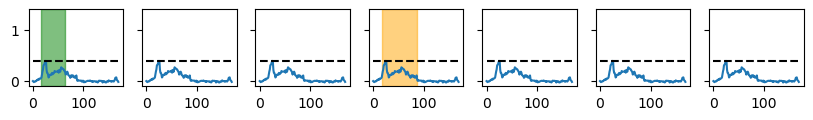

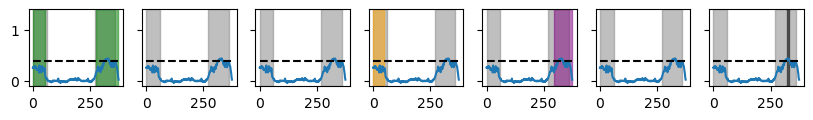

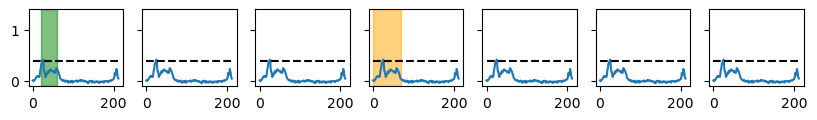

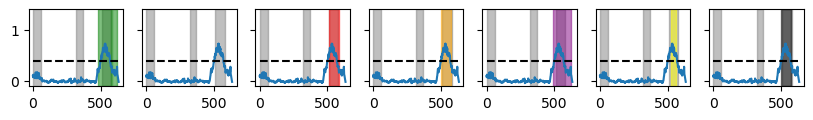

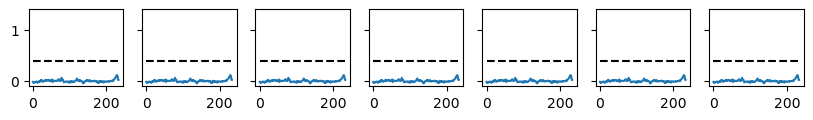

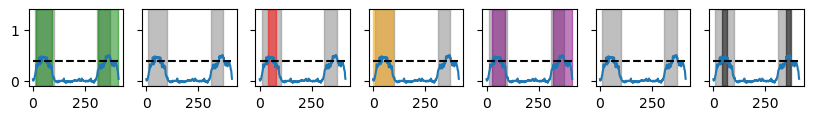

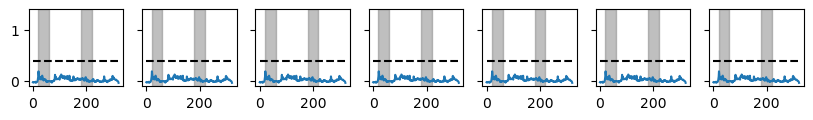

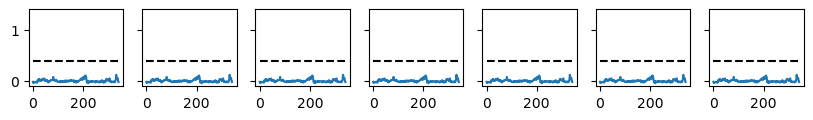

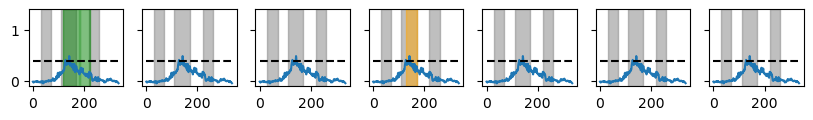

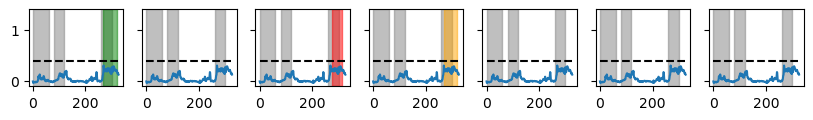

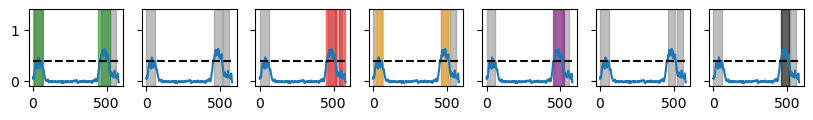

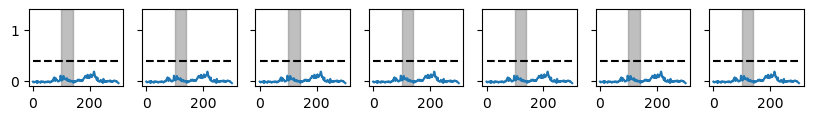

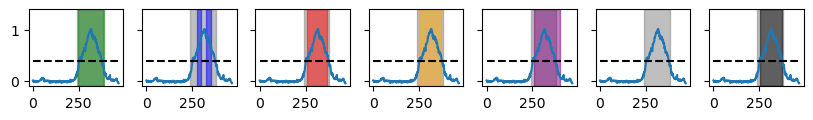

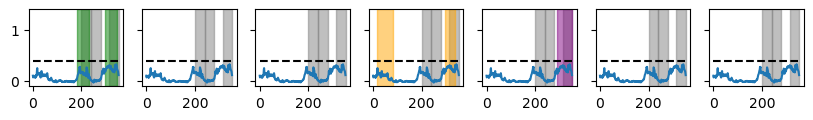

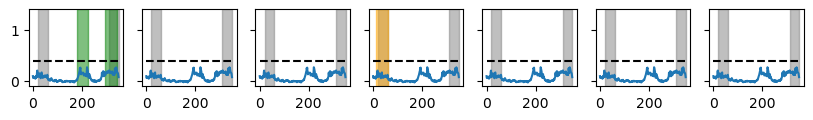

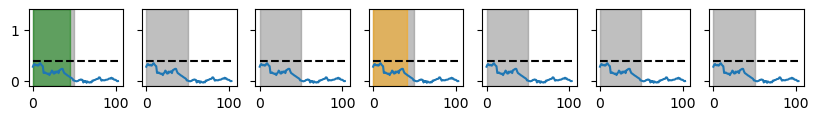

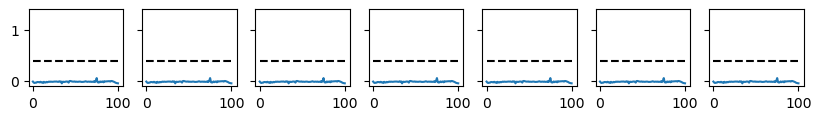

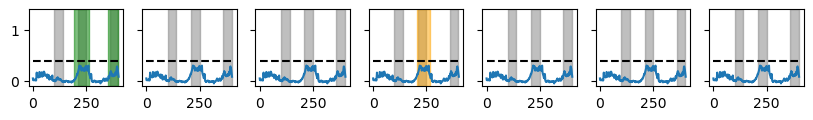

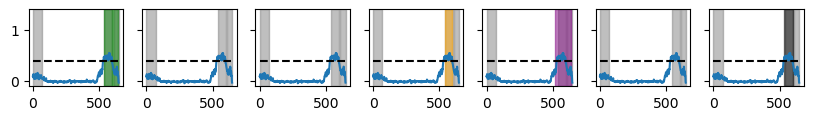

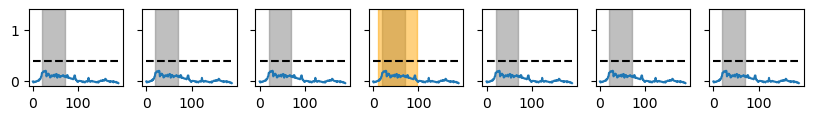

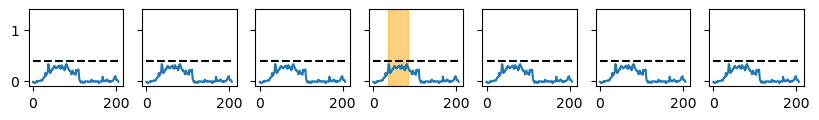

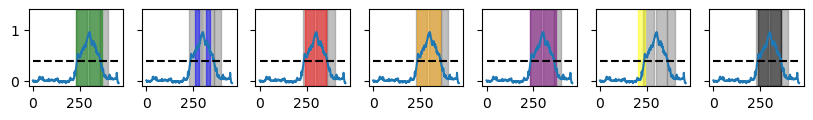

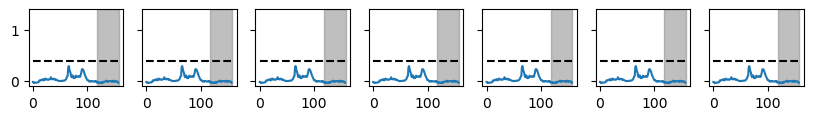

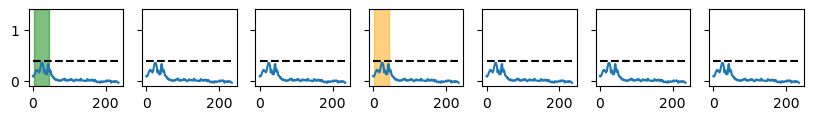

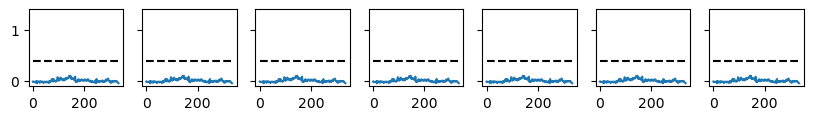

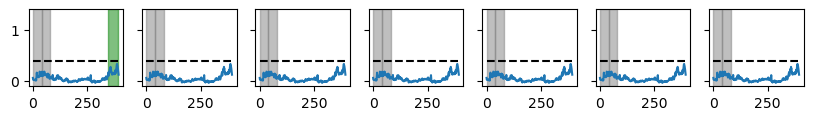

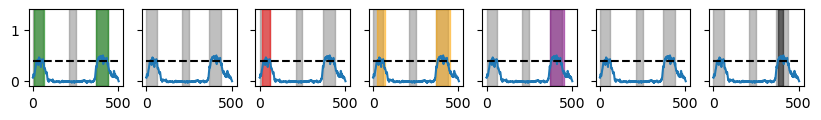

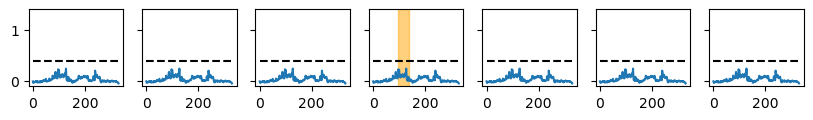

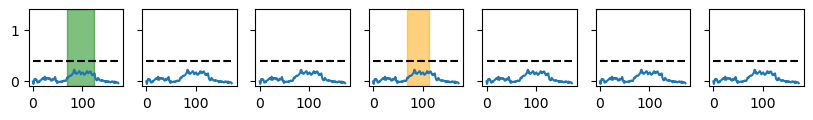

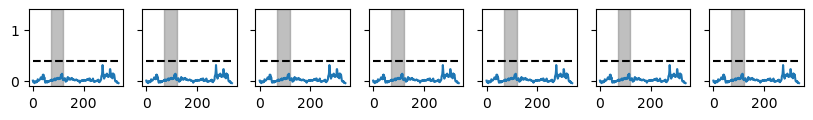

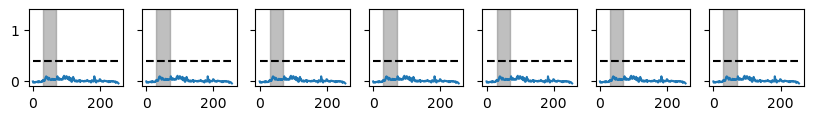

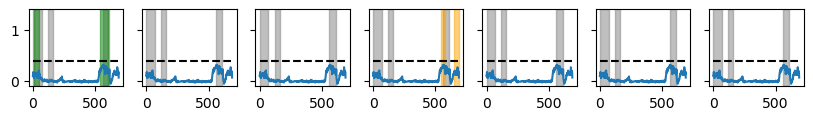

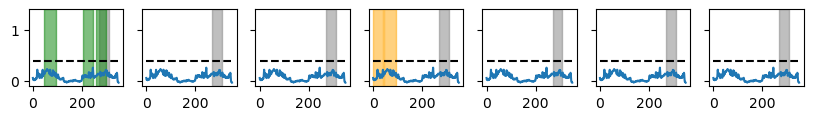

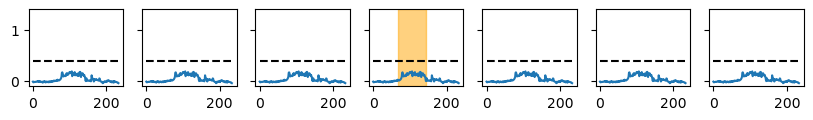

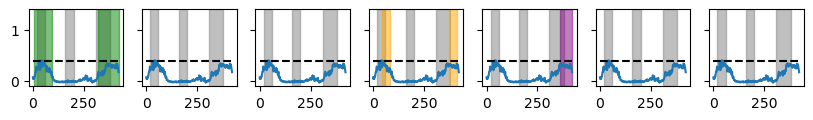

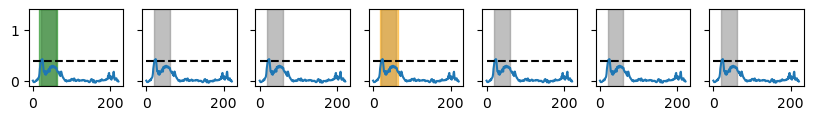

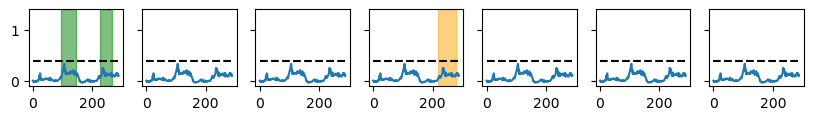

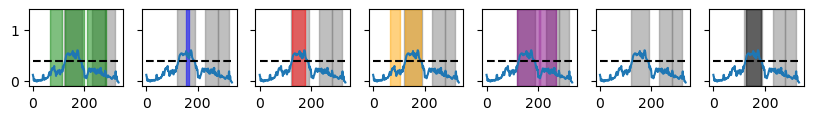

In [45]:
for i in range(len(merged_consensus)): 
    fig, axs = plt.subplots(1, 7, figsize=(10, 1), sharey=True)
    for j in range(7):
        axs[j].plot(merged_consensus.loc[i, 'preds'])
        for start, end in merged_consensus.loc[i, 'real_AD_coords']:
            axs[j].axvspan(start, end, color='grey', alpha=0.5)
        axs[j].hlines(0.4, 0, len(merged_consensus.loc[i, 'sequence']), color='black', linestyle='--')

    for start, end in merged_individual.loc[i, 'tada_intervals']: 
        axs[0].axvspan(start, end, color='green', alpha=0.5)
    
    for start, end in merged_individual.loc[i, 'adpred_intervals']: 
        axs[1].axvspan(start, end, color='blue', alpha=0.5)

    for start, end in merged_individual.loc[i, 'adhunter_ensemble_intervals']: 
        axs[2].axvspan(start, end, color='red', alpha=0.5)

    for start, end in merged_individual.loc[i, 'adhunter_intervals']: 
        axs[3].axvspan(start, end, color='orange', alpha=0.5)

    for start, end in merged_individual.loc[i, 'paddle_intervals']: 
        axs[4].axvspan(start, end, color='purple', alpha=0.5)
    
    for start, end in merged_individual.loc[i, 'composition_intervals']: 
        axs[5].axvspan(start, end, color='yellow', alpha=0.5)

    for start, end in merged_consensus.loc[i, 'predicted_AD_coords']: 
        axs[6].axvspan(start, end, color='black', alpha=0.5)



    axs[0].set_ylim(-0.1, 1.4)
    plt.show()